<a href="https://colab.research.google.com/github/Kevs-CPU/CPR-SIMULATION/blob/main/CPR_Original_Baseline_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install mediapipe opencv-python pandas matplotlib

In [ ]:
# Import required libraries

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check installed versions

print("OpenCV Version:", cv2.__version__)
print("MediaPipe Version:", mp.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

# Verify MediaPipe Tasks API

print("MediaPipe Tasks Available:", hasattr(mp, "tasks"))

OpenCV Version: 5.0.0
MediaPipe Version: 1.2.3
NumPy Version: 2.4.6
Pandas Version: 2.2.3
MediaPipe Tasks Available: True


In [ ]:
# Download MediaPipe Pose Landmarker Full Model

!wget -q -O pose_landmarker_full.task \
"https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task"

# Verify downloaded model

import os

model_path = "pose_landmarker_full.task"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)

    print("Model downloaded successfully!")
    print("Model name:", model_path)
    print(f"File size: {size_mb:.2f} MB")
else:
    print("Model download failed.")

Model downloaded successfully!
Model name: pose_landmarker_full.task
File size: 8.96 MB


In [ ]:
# CELL 4: Initialize MediaPipe Pose Landmarker

import os
import mediapipe as mp

model_path = "pose_landmarker_full.task"

# Check model file
assert os.path.exists(model_path), "Pose model not found!"

# Configure MediaPipe
BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

# Set baseline configuration
options = PoseLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=model_path
    ),
    running_mode=RunningMode.VIDEO,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

# Initialize detector
with PoseLandmarker.create_from_options(options) as landmarker:
    print("Pose Landmarker initialized successfully!")
    print("Running Mode: VIDEO")
    print("Maximum Poses:", 1)
    print("Expected Landmarks per Detected Person: 33")

Pose Landmarker initialized successfully!
Running Mode: VIDEO
Maximum Poses: 1
Expected Landmarks per Detected Person: 33


In [ ]:

# CELL 5B: LIVE MEDIAPIPE HAND SKELETON
# Google Colab + Webcam + 21 Hand Landmarks

from IPython.display import display, Javascript
from google.colab.output import eval_js

display(Javascript(r"""
window.startColabHandLandmarker = async function() {

    const previous = document.getElementById("colab-hand-demo");
    if (previous) previous.remove();

    const box = document.createElement("div");
    box.id = "colab-hand-demo";
    box.style.cssText = "max-width:680px;padding:12px;border:1px solid #888;border-radius:8px;font-family:Arial";

    const title = document.createElement("h3");
    title.textContent = "MediaPipe Live Hand Skeleton";

    const status = document.createElement("p");
    status.textContent = "Loading Hand Landmarker model...";

    const canvas = document.createElement("canvas");
    canvas.width = 640;
    canvas.height = 480;
    canvas.style.cssText = "width:100%;max-width:640px;border:2px solid #777;border-radius:8px";

    const video = document.createElement("video");
    video.autoplay = true;
    video.playsInline = true;
    video.muted = true;

    const stopButton = document.createElement("button");
    stopButton.textContent = "Stop Webcam";
    stopButton.style.cssText = "padding:10px;margin-top:10px;cursor:pointer";

    box.append(title, status, canvas, stopButton);
    document.body.appendChild(box);

    const ctx = canvas.getContext("2d");

    let stream = null;
    let landmarker = null;
    let running = false;
    let animationFrame = null;
    let lastVideoTime = -1;

    const CONNECTIONS = [
        [0,1],[1,2],[2,3],[3,4],
        [0,5],[5,6],[6,7],[7,8],
        [5,9],[9,10],[10,11],[11,12],
        [9,13],[13,14],[14,15],[15,16],
        [13,17],[17,18],[18,19],[19,20],
        [0,17]
    ];

    function drawHand(results) {

        ctx.clearRect(0, 0, canvas.width, canvas.height);

        ctx.drawImage(
            video, 0, 0,
            canvas.width, canvas.height
        );

        if (!results.landmarks || results.landmarks.length === 0) {
            status.textContent = "No hand detected. Show your open palm.";
            return;
        }

        results.landmarks.forEach((landmarks, handIndex) => {

            const points = landmarks.map(point => ({
                x: point.x * canvas.width,
                y: point.y * canvas.height
            }));

            // GREEN SKELETON LINES
            ctx.strokeStyle = "#00ff35";
            ctx.lineWidth = 4;
            ctx.lineCap = "round";

            CONNECTIONS.forEach(([start, end]) => {

                ctx.beginPath();
                ctx.moveTo(points[start].x, points[start].y);
                ctx.lineTo(points[end].x, points[end].y);
                ctx.stroke();

            });

            // RED LANDMARK POINTS + NUMBER LABELS
            points.forEach((point, index) => {

                ctx.beginPath();
                ctx.arc(point.x, point.y, 6, 0, Math.PI * 2);

                ctx.fillStyle = "#ff1b1b";
                ctx.fill();

                ctx.strokeStyle = "white";
                ctx.lineWidth = 1.5;
                ctx.stroke();

                ctx.font = "bold 14px Arial";
                ctx.lineWidth = 3;
                ctx.strokeStyle = "white";
                ctx.strokeText(
                    String(index),
                    point.x - 17,
                    point.y - 9
                );

                ctx.fillStyle = "black";
                ctx.fillText(
                    String(index),
                    point.x - 17,
                    point.y - 9
                );

            });

        });

        const handCount = results.landmarks.length;

        const handedness =
            results.handedness?.[0]?.[0]?.categoryName ||
            results.handednesses?.[0]?.[0]?.categoryName ||
            "Unknown";

        status.textContent =
            "SUCCESS | " + handCount +
            " hand(s) detected | " +
            handedness + " | 21 landmarks";
    }

    function stopCamera() {

        running = false;

        if (animationFrame !== null) {
            cancelAnimationFrame(animationFrame);
        }

        if (stream) {
            stream.getTracks().forEach(track => track.stop());
            stream = null;
        }

        video.srcObject = null;

        if (landmarker) {
            landmarker.close();
            landmarker = null;
        }

        ctx.clearRect(0, 0, canvas.width, canvas.height);

        status.textContent = "Webcam stopped.";
        stopButton.disabled = true;

    }

    stopButton.onclick = stopCamera;

    try {

        // LOAD MEDIAPIPE LIBRARY
        const {
            FilesetResolver,
            HandLandmarker
        } = await import(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/vision_bundle.mjs"
        );

        const vision = await FilesetResolver.forVisionTasks(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/wasm"
        );

        status.textContent = "Downloading Hand Landmarker model...";

        // INITIALIZE HAND LANDMARKER
        landmarker = await HandLandmarker.createFromOptions(
            vision,
            {
                baseOptions: {
                    modelAssetPath:
                    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
                },
                runningMode: "VIDEO",
                numHands: 1,
                minHandDetectionConfidence: 0.5,
                minHandPresenceConfidence: 0.5,
                minTrackingConfidence: 0.5
            }
        );

        status.textContent = "Starting webcam...";

        stream = await navigator.mediaDevices.getUserMedia({
            video: {
                width: { ideal: 640 },
                height: { ideal: 480 }
            },
            audio: false
        });

        video.srcObject = stream;
        await video.play();

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        running = true;

        status.textContent = "Hand Landmarker is running!";

        function renderFrame() {

            if (!running) return;

            if (video.readyState >= 2 &&
                video.currentTime !== lastVideoTime) {

                lastVideoTime = video.currentTime;

                const results = landmarker.detectForVideo(
                    video,
                    performance.now()
                );

                drawHand(results);
            }

            animationFrame = requestAnimationFrame(renderFrame);
        }

        renderFrame();

        return "SUCCESS: Live Hand Skeleton Detection Started!";

    } catch(error) {

        stopCamera();

        status.textContent =
            "ERROR: " + error.name + " - " + error.message;

        return "ERROR: " + error.message;
    }
};
"""))

result = eval_js("startColabHandLandmarker()")
print(result)


In [ ]:

# CELL 6: LIVE MEDIAPIPE FULL BODY POSE DETECTION
# Google Colab + Webcam + 33 Body Landmarks

from IPython.display import display, Javascript
from google.colab.output import eval_js

display(Javascript(r"""
window.startColabPoseTest = async function() {

    const previous = document.getElementById("colab-pose-demo");
    if (previous) previous.remove();

    const box = document.createElement("div");
    box.id = "colab-pose-demo";
    box.style.cssText =
        "max-width:700px;padding:12px;border:1px solid #888;" +
        "border-radius:8px;font-family:Arial";

    const title = document.createElement("h3");
    title.textContent = "MediaPipe Live Full-Body Pose Detection";

    const status = document.createElement("p");
    status.textContent = "Loading Pose Landmarker...";

    const canvas = document.createElement("canvas");
    canvas.width = 640;
    canvas.height = 480;
    canvas.style.cssText =
        "width:100%;max-width:640px;border:2px solid #777;" +
        "border-radius:8px";

    const video = document.createElement("video");
    video.autoplay = true;
    video.playsInline = true;
    video.muted = true;

    const stopButton = document.createElement("button");
    stopButton.textContent = "Stop Webcam";
    stopButton.style.cssText = "padding:10px;margin-top:10px";

    box.append(title, status, canvas, stopButton);
    document.body.appendChild(box);

    const ctx = canvas.getContext("2d");

    let stream = null;
    let landmarker = null;
    let drawingUtils = null;
    let running = false;
    let animationFrame = null;
    let lastVideoTime = -1;

    function stopCamera() {

        running = false;

        if (animationFrame !== null) {
            cancelAnimationFrame(animationFrame);
            animationFrame = null;
        }

        if (stream) {
            stream.getTracks().forEach(track => track.stop());
            stream = null;
        }

        video.srcObject = null;

        if (landmarker) {
            landmarker.close();
            landmarker = null;
        }

        ctx.clearRect(0, 0, canvas.width, canvas.height);

        stopButton.disabled = true;
        status.textContent = "Webcam stopped.";
    }

    stopButton.onclick = stopCamera;

    try {

        // LOAD MEDIAPIPE VISION LIBRARY
        const {
            FilesetResolver,
            PoseLandmarker,
            DrawingUtils
        } = await import(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/vision_bundle.mjs"
        );

        const vision = await FilesetResolver.forVisionTasks(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/wasm"
        );

        status.textContent = "Initializing Full Pose Model...";

        // INITIALIZE FULL POSE LANDMARKER
        landmarker = await PoseLandmarker.createFromOptions(
            vision,
            {
                baseOptions: {
                    modelAssetPath:
                    "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task"
                },
                runningMode: "VIDEO",
                numPoses: 1,
                minPoseDetectionConfidence: 0.5,
                minPosePresenceConfidence: 0.5,
                minTrackingConfidence: 0.5
            }
        );

        drawingUtils = new DrawingUtils(ctx);

        status.textContent = "Requesting webcam...";

        // START WEBCAM
        stream = await navigator.mediaDevices.getUserMedia({
            video: {
                width: { ideal: 640 },
                height: { ideal: 480 }
            },
            audio: false
        });

        video.srcObject = stream;
        await video.play();

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        running = true;
        stopButton.disabled = false;

        status.textContent = "Pose Detection Running...";

        // LIVE DETECTION LOOP
        function renderFrame() {

            if (!running) return;

            if (
                video.readyState >= 2 &&
                video.currentTime !== lastVideoTime
            ) {

                lastVideoTime = video.currentTime;

                const results = landmarker.detectForVideo(
                    video,
                    performance.now()
                );

                ctx.clearRect(
                    0, 0, canvas.width, canvas.height
                );

                ctx.drawImage(
                    video, 0, 0,
                    canvas.width, canvas.height
                );

                if (
                    results.landmarks &&
                    results.landmarks.length > 0
                ) {

                    results.landmarks.forEach(pose => {

                        // GREEN BODY SKELETON
                        drawingUtils.drawConnectors(
                            pose,
                            PoseLandmarker.POSE_CONNECTIONS,
                            {
                                color: "#00FF35",
                                lineWidth: 4
                            }
                        );

                        // RED BODY LANDMARKS
                        drawingUtils.drawLandmarks(
                            pose,
                            {
                                color: "#FF2020",
                                fillColor: "#FF2020",
                                lineWidth: 1,
                                radius: 5
                            }
                        );

                    });

                    status.textContent =
                        "SUCCESS | Body detected | " +
                        results.landmarks[0].length +
                        " landmarks detected";

                } else {

                    status.textContent =
                        "No body detected. Move farther from camera.";
                }
            }

            animationFrame = requestAnimationFrame(renderFrame);
        }

        renderFrame();

        return "SUCCESS: Full Body Pose Detection Started!";

    } catch(error) {

        stopCamera();

        status.textContent =
            "ERROR: " + error.name + " - " + error.message;

        return "ERROR: " + error.message;
    }

};
"""))

result = eval_js("startColabPoseTest()")
print(result)


In [ ]:

# =========================================================
# CELL 7: HAND + BODY TRACKING INTEGRATION
# Google Colab + One Webcam + MediaPipe Tasks Vision
# 33 Body Landmarks + 21 Hand Landmarks
# =========================================================

from IPython.display import display, Javascript
from google.colab.output import eval_js

display(Javascript(r"""

window.startIntegratedTracking = async function() {

    // Stop previous integration session, if any
    if (window.stopIntegratedTracking) {
        window.stopIntegratedTracking();
    }

    const previous = document.getElementById("integrated-demo");
    if (previous) previous.remove();

    // CREATE INTERFACE
    const box = document.createElement("div");
    box.id = "integrated-demo";
    box.style.cssText =
        "max-width:750px;padding:14px;border:1px solid #888;" +
        "border-radius:10px;font-family:Arial";

    const title = document.createElement("h3");
    title.textContent = "Live Hand + Body Tracking";

    const status = document.createElement("p");
    status.textContent = "Loading MediaPipe models...";

    const canvas = document.createElement("canvas");
    canvas.width = 640;
    canvas.height = 480;
    canvas.style.cssText =
        "width:100%;max-width:700px;border:2px solid #777;" +
        "border-radius:8px";

    const video = document.createElement("video");
    video.autoplay = true;
    video.playsInline = true;
    video.muted = true;

    const stopButton = document.createElement("button");
    stopButton.textContent = "Stop Webcam";
    stopButton.style.cssText =
        "padding:10px 18px;margin-top:12px;cursor:pointer;" +
        "background:#dc3545;color:white;border:0;border-radius:5px";

    box.append(title, status, canvas, stopButton);
    document.body.appendChild(box);

    const ctx = canvas.getContext("2d");

    // CONNECTIONS BETWEEN 21 HAND LANDMARKS
    const HAND_CONNECTIONS = [
        [0,1], [1,2], [2,3], [3,4],
        [0,5], [5,6], [6,7], [7,8],
        [5,9], [9,10], [10,11], [11,12],
        [9,13], [13,14], [14,15], [15,16],
        [13,17], [17,18], [18,19], [19,20],
        [0,17]
    ];

    let stream = null;
    let poseLandmarker = null;
    let handLandmarker = null;
    let drawingUtils = null;

    let running = false;
    let animationFrame = null;
    let lastVideoTime = -1;
    let lastProcessTime = 0;

    // STOP EVERYTHING
    function stopCamera() {

        running = false;

        if (animationFrame !== null) {
            cancelAnimationFrame(animationFrame);
            animationFrame = null;
        }

        if (stream) {
            stream.getTracks().forEach(track => track.stop());
            stream = null;
        }

        video.srcObject = null;

        if (poseLandmarker) {
            poseLandmarker.close();
            poseLandmarker = null;
        }

        if (handLandmarker) {
            handLandmarker.close();
            handLandmarker = null;
        }

        ctx.clearRect(0, 0, canvas.width, canvas.height);

        stopButton.disabled = true;
        status.textContent = "Webcam stopped.";

        window.stopIntegratedTracking = null;
    }

    window.stopIntegratedTracking = stopCamera;
    stopButton.onclick = stopCamera;

    try {

        // -------------------------------------------------
        // 1. LOAD MEDIAPIPE LIBRARY
        // -------------------------------------------------

        const {
            FilesetResolver,
            HandLandmarker,
            PoseLandmarker,
            DrawingUtils
        } = await import(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/vision_bundle.mjs"
        );

        const vision = await FilesetResolver.forVisionTasks(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/wasm"
        );

        // -------------------------------------------------
        // 2. INITIALIZE BODY POSE LANDMARKER
        // -------------------------------------------------

        status.textContent = "Initializing Body Pose Model...";

        poseLandmarker = await PoseLandmarker.createFromOptions(
            vision,
            {
                baseOptions: {
                    modelAssetPath:
                    "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task"
                },

                runningMode: "VIDEO",
                numPoses: 1,

                minPoseDetectionConfidence: 0.5,
                minPosePresenceConfidence: 0.5,
                minTrackingConfidence: 0.5
            }
        );

        // -------------------------------------------------
        // 3. INITIALIZE HAND LANDMARKER
        // -------------------------------------------------

        status.textContent = "Initializing Hand Model...";

        handLandmarker = await HandLandmarker.createFromOptions(
            vision,
            {
                baseOptions: {
                    modelAssetPath:
                    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
                },

                runningMode: "VIDEO",
                numHands: 1,

                minHandDetectionConfidence: 0.5,
                minHandPresenceConfidence: 0.5,
                minTrackingConfidence: 0.5
            }
        );

        drawingUtils = new DrawingUtils(ctx);

        // -------------------------------------------------
        // 4. START ONE WEBCAM STREAM
        // -------------------------------------------------

        status.textContent = "Connecting to webcam...";

        stream = await navigator.mediaDevices.getUserMedia({
            video: {
                width: { ideal: 640 },
                height: { ideal: 480 },
                frameRate: { ideal: 20 }
            },
            audio: false
        });

        video.srcObject = stream;
        await video.play();

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        running = true;
        stopButton.disabled = false;

        status.textContent = "Integrated tracking started!";

        // -------------------------------------------------
        // 5. DRAW HAND SKELETON
        // -------------------------------------------------

        function drawHand(handLandmarks, handSide) {

            const points = handLandmarks.map(point => ({
                x: point.x * canvas.width,
                y: point.y * canvas.height
            }));

            // CYAN HAND CONNECTIONS
            ctx.strokeStyle = "#00E5FF";
            ctx.lineWidth = 3;
            ctx.lineCap = "round";

            HAND_CONNECTIONS.forEach(([a, b]) => {

                ctx.beginPath();
                ctx.moveTo(points[a].x, points[a].y);
                ctx.lineTo(points[b].x, points[b].y);
                ctx.stroke();

            });

            // YELLOW HAND LANDMARKS
            points.forEach((point, index) => {

                ctx.beginPath();

                ctx.arc(
                    point.x,
                    point.y,
                    5,
                    0,
                    Math.PI * 2
                );

                ctx.fillStyle = "#FFE600";
                ctx.fill();

                ctx.lineWidth = 1.5;
                ctx.strokeStyle = "#222";
                ctx.stroke();

                // LANDMARK NUMBER
                ctx.font = "bold 12px Arial";
                ctx.lineWidth = 3;
                ctx.strokeStyle = "white";

                ctx.strokeText(
                    String(index),
                    point.x - 15,
                    point.y - 8
                );

                ctx.fillStyle = "#111";

                ctx.fillText(
                    String(index),
                    point.x - 15,
                    point.y - 8
                );

            });

            // HAND LABEL
            ctx.font = "bold 15px Arial";
            ctx.fillStyle = "#FFE600";

            ctx.fillText(
                handSide,
                points[0].x + 10,
                points[0].y - 12
            );
        }

        // -------------------------------------------------
        // 6. LIVE INTEGRATED DETECTION
        // -------------------------------------------------

        function renderFrame(now) {

            if (!running) return;

            // Limit processing to approximately 20 FPS
            if (
                video.readyState >= 2 &&
                video.currentTime !== lastVideoTime &&
                now - lastProcessTime >= 50
            ) {

                lastVideoTime = video.currentTime;
                lastProcessTime = now;

                const timestamp = Math.round(now);

                // SAME FRAME SENT TO BOTH MODELS
                const poseResults =
                    poseLandmarker.detectForVideo(
                        video,
                        timestamp
                    );

                const handResults =
                    handLandmarker.detectForVideo(
                        video,
                        timestamp
                    );

                // DRAW CAMERA IMAGE
                ctx.clearRect(
                    0, 0,
                    canvas.width,
                    canvas.height
                );

                ctx.drawImage(
                    video,
                    0, 0,
                    canvas.width,
                    canvas.height
                );

                // -------------------------------------------------
                // DRAW 33 BODY LANDMARKS
                // -------------------------------------------------

                const body = poseResults.landmarks || [];
                const bodyCount = body.length > 0
                    ? body[0].length
                    : 0;

                body.forEach(pose => {

                    // BODY CONNECTIONS: GREEN
                    drawingUtils.drawConnectors(
                        pose,
                        PoseLandmarker.POSE_CONNECTIONS,
                        {
                            color: "#00FF35",
                            lineWidth: 3
                        }
                    );

                    // BODY POINTS: RED
                    drawingUtils.drawLandmarks(
                        pose,
                        {
                            color: "#FF2020",
                            fillColor: "#FF2020",
                            lineWidth: 1,
                            radius: 4
                        }
                    );

                });

                // -------------------------------------------------
                // DRAW 21 HAND LANDMARKS
                // -------------------------------------------------

                const hands = handResults.landmarks || [];

                let handLandmarkCount = 0;

                hands.forEach((hand, index) => {

                    handLandmarkCount += hand.length;

                    const handSide =
                        handResults.handedness?.[index]?.[0]?.categoryName ||
                        "Hand";

                    drawHand(hand, handSide);

                });

                // -------------------------------------------------
                // 7. INTEGRATED DETECTION STATUS
                // -------------------------------------------------

                const combinedCount =
                    bodyCount + handLandmarkCount;

                status.textContent =
                    "BODY: " + bodyCount + "/33" +
                    " | HANDS: " + hands.length +
                    " | HAND LANDMARKS: " + handLandmarkCount +
                    " | COMBINED: " + combinedCount;

            }

            animationFrame = requestAnimationFrame(renderFrame);
        }

        renderFrame(performance.now());

        return "SUCCESS: Hand + Body Tracking Started!";

    } catch(error) {

        stopCamera();

        status.textContent =
            "ERROR: " + error.name + " - " + error.message;

        return "ERROR: " + error.message;
    }

};
"""))

result = eval_js("startIntegratedTracking()")
print(result)


In [ ]:

# =========================================================
# CELL 8: LANDMARK DATA COLLECTION
# MediaPipe Hand + Body Tracking
# Google Colab + Webcam + CSV Export
# =========================================================

from IPython.display import display, Javascript
from google.colab.output import eval_js

display(Javascript(r"""

window.startCell8Collection = async function() {

    // CLEAN UP PREVIOUS SESSION
    if (window.stopCell8Collection) {
        window.stopCell8Collection();
    }

    const previous = document.getElementById("cell8-collector");
    if (previous) previous.remove();

    // -----------------------------------------------------
    // 1. CREATE INTERFACE
    // -----------------------------------------------------

    const box = document.createElement("div");
    box.id = "cell8-collector";
    box.style.cssText =
        "max-width:750px;padding:14px;border:1px solid #888;" +
        "border-radius:10px;font-family:Arial";

    const title = document.createElement("h3");
    title.textContent = "Cell 8 - Landmark Data Collection";

    const status = document.createElement("p");
    status.textContent = "Loading MediaPipe models...";

    const canvas = document.createElement("canvas");
    canvas.width = 640;
    canvas.height = 480;
    canvas.style.cssText =
        "width:100%;max-width:700px;border:2px solid #777;" +
        "border-radius:8px";

    const video = document.createElement("video");
    video.autoplay = true;
    video.playsInline = true;
    video.muted = true;

    const stopButton = document.createElement("button");
    stopButton.textContent = "Stop & Prepare CSV";
    stopButton.style.cssText =
        "padding:11px 18px;margin-top:12px;" +
        "background:#dc3545;color:white;border:0;" +
        "border-radius:5px;cursor:pointer";

    const downloadPanel = document.createElement("div");
    downloadPanel.style.cssText = "margin-top:15px";

    box.append(title, status, canvas, stopButton, downloadPanel);
    document.body.appendChild(box);

    const ctx = canvas.getContext("2d");

    // -----------------------------------------------------
    // 2. LANDMARK NAMES
    // -----------------------------------------------------

    const POSE_NAMES = [
        "nose",
        "left_eye_inner", "left_eye", "left_eye_outer",
        "right_eye_inner", "right_eye", "right_eye_outer",
        "left_ear", "right_ear",
        "mouth_left", "mouth_right",
        "left_shoulder", "right_shoulder",
        "left_elbow", "right_elbow",
        "left_wrist", "right_wrist",
        "left_pinky", "right_pinky",
        "left_index", "right_index",
        "left_thumb", "right_thumb",
        "left_hip", "right_hip",
        "left_knee", "right_knee",
        "left_ankle", "right_ankle",
        "left_heel", "right_heel",
        "left_foot_index", "right_foot_index"
    ];

    const HAND_NAMES = [
        "wrist",
        "thumb_cmc",
        "thumb_mcp",
        "thumb_ip",
        "thumb_tip",
        "index_finger_mcp",
        "index_finger_pip",
        "index_finger_dip",
        "index_finger_tip",
        "middle_finger_mcp",
        "middle_finger_pip",
        "middle_finger_dip",
        "middle_finger_tip",
        "ring_finger_mcp",
        "ring_finger_pip",
        "ring_finger_dip",
        "ring_finger_tip",
        "pinky_finger_mcp",
        "pinky_finger_pip",
        "pinky_finger_dip",
        "pinky_finger_tip"
    ];

    const HAND_CONNECTIONS = [
        [0,1],[1,2],[2,3],[3,4],
        [0,5],[5,6],[6,7],[7,8],
        [5,9],[9,10],[10,11],[11,12],
        [9,13],[13,14],[14,15],[15,16],
        [13,17],[17,18],[18,19],[19,20],
        [0,17]
    ];

    // -----------------------------------------------------
    // 3. DATA STORAGE
    // -----------------------------------------------------

    const landmarkRows = [];
    const frameRows = [];

    const sessionId =
        "CPR_DATA_" + new Date().toISOString().replace(/[:.]/g, "-");

    let sessionStart = 0;
    let startUTC = "";
    let stream = null;
    let poseLandmarker = null;
    let handLandmarker = null;
    let drawingUtils = null;

    let running = false;
    let animationFrame = null;
    let lastVideoTime = -1;
    let lastProcessTime = 0;
    let lastTimestamp = 0;

    const SAMPLE_INTERVAL = 100; // Approximately 10 samples/sec

    // Helpers for CSV-safe values
    function valueOrBlank(value) {
        return value === undefined || value === null ||
               !Number.isFinite(value)
            ? ""
            : value;
    }

    function coordinate(value) {
        return Number(value.toFixed(7));
    }

    // -----------------------------------------------------
    // 4. RECORD LANDMARKS
    // -----------------------------------------------------

    function recordLandmarks(
        model,
        landmarks,
        worldLandmarks,
        names,
        subjectIndex,
        timestamp,
        elapsed,
        recordedAt,
        handedness,
        handednessScore
    ) {

        landmarks.forEach((point, index) => {

            const world = worldLandmarks[index] || {};

            const row = {

                session_id: sessionId,
                recorded_at_utc: recordedAt,
                timestamp_ms: timestamp,
                elapsed_ms: elapsed,

                model: model,
                subject_index: subjectIndex,

                landmark_index: index,
                landmark_name: names[index] || "unknown",

                // Normalized image coordinates
                x: coordinate(point.x),
                y: coordinate(point.y),
                z: coordinate(point.z),

                // Model world coordinates, when available
                world_x: valueOrBlank(world.x),
                world_y: valueOrBlank(world.y),
                world_z: valueOrBlank(world.z),

                // Pose confidence fields
                visibility: valueOrBlank(point.visibility),
                presence: valueOrBlank(point.presence),

                // Hand classification fields
                handedness: handedness || "",
                handedness_score: valueOrBlank(handednessScore)
            };

            landmarkRows.push(row);

        });
    }

    // -----------------------------------------------------
    // 5. CSV GENERATOR
    // -----------------------------------------------------

    function makeCSV(rows, columns) {

        function escapeCSV(value) {

            if (value === undefined || value === null) {
                return "";
            }

            const text = String(value);

            if (/[",\r\n]/.test(text)) {
                return '"' + text.replace(/"/g, '""') + '"';
            }

            return text;
        }

        const header = columns.join(",");

        const lines = rows.map(row =>
            columns.map(column =>
                escapeCSV(row[column])
            ).join(",")
        );

        return [header, ...lines].join("\r\n");
    }

    function createDownloadButton(label, filename, content) {

        const button = document.createElement("button");

        button.textContent = label;
        button.style.cssText =
            "padding:10px;margin:5px 5px 5px 0;" +
            "background:#198754;color:white;border:0;" +
            "border-radius:5px;cursor:pointer";

        button.onclick = () => {

            const blob = new Blob(
                ["\uFEFF" + content],
                { type: "text/csv;charset=utf-8;" }
            );

            const url = URL.createObjectURL(blob);

            const anchor = document.createElement("a");
            anchor.href = url;
            anchor.download = filename;

            document.body.appendChild(anchor);
            anchor.click();
            anchor.remove();

            setTimeout(() => URL.revokeObjectURL(url), 10000);

        };

        downloadPanel.appendChild(button);
    }

    // -----------------------------------------------------
    // 6. STOP AND EXPORT
    // -----------------------------------------------------

    function stopCapture() {

        if (!running && !stream) return;

        running = false;

        if (animationFrame !== null) {
            cancelAnimationFrame(animationFrame);
            animationFrame = null;
        }

        if (stream) {
            stream.getTracks().forEach(track => track.stop());
            stream = null;
        }

        video.srcObject = null;

        if (poseLandmarker) {
            poseLandmarker.close();
            poseLandmarker = null;
        }

        if (handLandmarker) {
            handLandmarker.close();
            handLandmarker = null;
        }

        stopButton.disabled = true;

        // Keep collected data available in this notebook page
        window.cell8LandmarkRows = landmarkRows;
        window.cell8FrameRows = frameRows;

        status.textContent =
            "COLLECTION COMPLETE | Frames: " +
            frameRows.length +
            " | Landmark rows: " +
            landmarkRows.length;

        // LANDMARK DATA CSV
        const landmarkColumns = [
            "session_id",
            "recorded_at_utc",
            "timestamp_ms",
            "elapsed_ms",
            "model",
            "subject_index",
            "landmark_index",
            "landmark_name",
            "x", "y", "z",
            "world_x", "world_y", "world_z",
            "visibility",
            "presence",
            "handedness",
            "handedness_score"
        ];

        // FRAME SUMMARY CSV
        const frameColumns = [
            "session_id",
            "recorded_at_utc",
            "timestamp_ms",
            "elapsed_ms",
            "pose_detected",
            "pose_landmark_count",
            "hands_detected",
            "hand_landmark_count",
            "handedness",
            "handedness_score"
        ];

        const landmarkCSV = makeCSV(
            landmarkRows,
            landmarkColumns
        );

        const frameCSV = makeCSV(
            frameRows,
            frameColumns
        );

        const heading = document.createElement("h4");
        heading.textContent = "Download Collected Dataset";

        const info = document.createElement("p");
        info.textContent =
            "Frames: " + frameRows.length +
            " | Landmark records: " + landmarkRows.length;

        downloadPanel.append(heading, info);

        createDownloadButton(
            "Download Landmark Coordinates CSV",
            "cpr_landmark_coordinates.csv",
            landmarkCSV
        );

        createDownloadButton(
            "Download Frame Summary CSV",
            "cpr_frame_summary.csv",
            frameCSV
        );

        const note = document.createElement("p");
        note.textContent =
            "Download both CSV files and keep them for Cell 9.";

        downloadPanel.appendChild(note);

    }

    window.stopCell8Collection = stopCapture;

    stopButton.onclick = stopCapture;

    // -----------------------------------------------------
    // 7. INITIALIZE BOTH MEDIAPIPE MODELS
    // -----------------------------------------------------

    try {

        const {
            FilesetResolver,
            PoseLandmarker,
            HandLandmarker,
            DrawingUtils
        } = await import(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/vision_bundle.mjs"
        );

        const vision = await FilesetResolver.forVisionTasks(
            "https://cdn.jsdelivr.net/npm/@mediapipe/tasks-vision@0.10.18/wasm"
        );

        status.textContent = "Initializing Pose Landmarker...";

        poseLandmarker = await PoseLandmarker.createFromOptions(
            vision,
            {
                baseOptions: {
                    modelAssetPath:
                    "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task"
                },
                runningMode: "VIDEO",
                numPoses: 1,
                minPoseDetectionConfidence: 0.5,
                minPosePresenceConfidence: 0.5,
                minTrackingConfidence: 0.5
            }
        );

        status.textContent = "Initializing Hand Landmarker...";

        handLandmarker = await HandLandmarker.createFromOptions(
            vision,
            {
                baseOptions: {
                    modelAssetPath:
                    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
                },
                runningMode: "VIDEO",
                numHands: 1,
                minHandDetectionConfidence: 0.5,
                minHandPresenceConfidence: 0.5,
                minTrackingConfidence: 0.5
            }
        );

        drawingUtils = new DrawingUtils(ctx);

        // -------------------------------------------------
        // 8. START ONE CAMERA
        // -------------------------------------------------

        status.textContent = "Requesting webcam...";

        stream = await navigator.mediaDevices.getUserMedia({
            video: {
                width: { ideal: 640 },
                height: { ideal: 480 },
                frameRate: { ideal: 20 }
            },
            audio: false
        });

        video.srcObject = stream;
        await video.play();

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        sessionStart = performance.now();
        startUTC = new Date().toISOString();

        running = true;
        stopButton.disabled = false;

        status.textContent =
            "RECORDING | Show your body and one hand.";

        // -------------------------------------------------
        // 9. LIVE RECORDING LOOP
        // -------------------------------------------------

        function renderFrame(now) {

            if (!running) return;

            if (
                video.readyState >= 2 &&
                video.currentTime !== lastVideoTime &&
                now - lastProcessTime >= SAMPLE_INTERVAL
            ) {

                lastVideoTime = video.currentTime;
                lastProcessTime = now;

                const timestamp = Math.max(
                    Math.round(now),
                    lastTimestamp + 1
                );

                lastTimestamp = timestamp;

                const elapsed = Math.round(now - sessionStart);
                const recordedAt = new Date().toISOString();

                // Same camera frame, two models
                const poseResults = poseLandmarker.detectForVideo(
                    video,
                    timestamp
                );

                const handResults = handLandmarker.detectForVideo(
                    video,
                    timestamp
                );

                const poses = poseResults.landmarks || [];
                const poseWorld = poseResults.worldLandmarks || [];

                const hands = handResults.landmarks || [];
                const handWorld = handResults.worldLandmarks || [];

                const handednessList =
                    handResults.handednesses ||
                    handResults.handedness ||
                    [];

                let poseCount = 0;
                let handCount = 0;

                // -----------------------------------------
                // RECORD BODY LANDMARKS
                // -----------------------------------------

                poses.forEach((pose, poseIndex) => {

                    poseCount += pose.length;

                    recordLandmarks(
                        "pose",
                        pose,
                        poseWorld[poseIndex] || [],
                        POSE_NAMES,
                        poseIndex,
                        timestamp,
                        elapsed,
                        recordedAt,
                        "",
                        null
                    );

                });

                // -----------------------------------------
                // RECORD HAND LANDMARKS
                // -----------------------------------------

                hands.forEach((hand, handIndex) => {

                    handCount += hand.length;

                    const category =
                        handednessList[handIndex]?.[0] || {};

                    const side = category.categoryName || "";
                    const score = category.score;

                    recordLandmarks(
                        "hand",
                        hand,
                        handWorld[handIndex] || [],
                        HAND_NAMES,
                        handIndex,
                        timestamp,
                        elapsed,
                        recordedAt,
                        side,
                        score
                    );

                });

                // -----------------------------------------
                // RECORD FRAME SUMMARY
                // -----------------------------------------

                frameRows.push({

                    session_id: sessionId,
                    recorded_at_utc: recordedAt,
                    timestamp_ms: timestamp,
                    elapsed_ms: elapsed,

                    pose_detected: poses.length > 0 ? 1 : 0,
                    pose_landmark_count: poseCount,

                    hands_detected: hands.length,
                    hand_landmark_count: handCount,

                    handedness:
                        handednessList[0]?.[0]?.categoryName || "",

                    handedness_score:
                        handednessList[0]?.[0]?.score ?? ""

                });

                // -----------------------------------------
                // DRAW VIDEO AND BODY SKELETON
                // -----------------------------------------

                ctx.clearRect(
                    0, 0, canvas.width, canvas.height
                );

                ctx.drawImage(
                    video,
                    0, 0,
                    canvas.width,
                    canvas.height
                );

                poses.forEach(pose => {

                    drawingUtils.drawConnectors(
                        pose,
                        PoseLandmarker.POSE_CONNECTIONS,
                        {
                            color: "#00FF35",
                            lineWidth: 3
                        }
                    );

                    drawingUtils.drawLandmarks(
                        pose,
                        {
                            color: "#FF2020",
                            fillColor: "#FF2020",
                            radius: 4
                        }
                    );

                });

                // -----------------------------------------
                // DRAW HAND SKELETON
                // -----------------------------------------

                hands.forEach((hand, handIndex) => {

                    const points = hand.map(point => ({
                        x: point.x * canvas.width,
                        y: point.y * canvas.height
                    }));

                    ctx.strokeStyle = "#00E5FF";
                    ctx.lineWidth = 3;

                    HAND_CONNECTIONS.forEach(([a, b]) => {

                        ctx.beginPath();
                        ctx.moveTo(points[a].x, points[a].y);
                        ctx.lineTo(points[b].x, points[b].y);
                        ctx.stroke();

                    });

                    points.forEach((point, index) => {

                        ctx.beginPath();
                        ctx.arc(
                            point.x,
                            point.y,
                            5,
                            0,
                            Math.PI * 2
                        );

                        ctx.fillStyle = "#FFE600";
                        ctx.fill();

                        ctx.strokeStyle = "#222";
                        ctx.stroke();

                    });

                });

                status.textContent =
                    "RECORDING | Frames: " + frameRows.length +
                    " | Body: " + poseCount + "/33" +
                    " | Hands: " + hands.length +
                    " | Hand points: " + handCount +
                    " | Total rows: " + landmarkRows.length;

            }

            animationFrame = requestAnimationFrame(renderFrame);

        }

        renderFrame(performance.now());

        return "SUCCESS: Cell 8 Data Collection Started!";

    } catch(error) {

        stopCapture();

        status.textContent =
            "ERROR: " + error.name + " - " + error.message;

        return "ERROR: " + error.message;

    }

};

"""))

result = eval_js("startCell8Collection()")
print(result)


<IPython.core.display.Javascript object>

SUCCESS: Cell 8 Data Collection Started!


In [ ]:

# ============================================================
# CELL 9: CPR MOVEMENT ANALYSIS
# Hand + Body Landmark Feature Extraction
# Google Colab + Pandas + NumPy + Matplotlib
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

print("CELL 9: CPR MOVEMENT ANALYSIS")
print("=" * 55)

# ------------------------------------------------------------
# 1. UPLOAD CELL 8 DATASETS
# ------------------------------------------------------------

print("\nUpload BOTH Cell 8 CSV files:")
print("1. cpr_landmark_coordinates.csv")
print("2. cpr_frame_summary.csv")

uploaded = files.upload()

landmark_file = next(
    (name for name in uploaded
     if "landmark_coordinates" in name.lower()),
    None
)

frame_file = next(
    (name for name in uploaded
     if "frame_summary" in name.lower()),
    None
)

if landmark_file is None or frame_file is None:
    raise FileNotFoundError(
        "Both Cell 8 CSV files are required."
    )

landmarks_df = pd.read_csv(landmark_file)
frames_df = pd.read_csv(frame_file)

required_columns = {
    "timestamp_ms", "elapsed_ms",
    "model", "landmark_index",
    "x", "y", "z"
}

missing = required_columns - set(landmarks_df.columns)

if missing:
    raise ValueError(
        f"Missing landmark columns: {missing}"
    )

print("\nDatasets loaded successfully!")
print("Landmark records:", len(landmarks_df))
print("Recorded frames:", len(frames_df))

# ------------------------------------------------------------
# 2. DATA CLEANING
# ------------------------------------------------------------

landmarks_df["model"] = (
    landmarks_df["model"].astype(str).str.lower()
)

for column in [
    "timestamp_ms", "elapsed_ms",
    "landmark_index", "subject_index",
    "x", "y", "z",
    "world_x", "world_y", "world_z",
    "visibility", "presence",
    "handedness_score"
]:
    if column in landmarks_df.columns:
        landmarks_df[column] = pd.to_numeric(
            landmarks_df[column],
            errors="coerce"
        )

for column in ["timestamp_ms", "elapsed_ms"]:
    frames_df[column] = pd.to_numeric(
        frames_df[column],
        errors="coerce"
    )

landmarks_df = landmarks_df.dropna(
    subset=["timestamp_ms", "landmark_index"]
)

frames_df = frames_df.dropna(
    subset=["timestamp_ms", "elapsed_ms"]
)

# ------------------------------------------------------------
# 3. LANDMARK INDEX REFERENCES
# ------------------------------------------------------------

# MediaPipe Pose landmark indices
BODY = {
    "left_shoulder": 11,
    "right_shoulder": 12,
    "left_elbow": 13,
    "right_elbow": 14,
    "left_wrist": 15,
    "right_wrist": 16,
    "left_hip": 23,
    "right_hip": 24
}

# MediaPipe Hand landmark index
HAND_WRIST = 0

# ------------------------------------------------------------
# 4. MATHEMATICAL FUNCTIONS
# ------------------------------------------------------------

def get_point(table, index, world=False):

    if table is None or index not in table.index:
        return None

    row = table.loc[index]

    prefix = "world_" if world else ""

    columns = [
        prefix + "x",
        prefix + "y",
        prefix + "z"
    ]

    values = []

    for column in columns:

        if column not in row.index:
            return None

        value = pd.to_numeric(
            row[column],
            errors="coerce"
        )

        if pd.isna(value):
            return None

        values.append(float(value))

    return np.array(values, dtype=float)


def get_visibility(table, index):

    if table is None or index not in table.index:
        return None

    if "visibility" not in table.columns:
        return None

    value = pd.to_numeric(
        table.loc[index, "visibility"],
        errors="coerce"
    )

    return None if pd.isna(value) else float(value)


def is_visible(table, indices, threshold=0.5):

    for index in indices:

        score = get_visibility(table, index)

        # If visibility is unavailable, retain the measurement.
        if score is not None and score < threshold:
            return False

    return True


def angle_between(a, b, c):

    """
    Calculate the angle at point B:
    A -------- B -------- C

    Output range: 0 to 180 degrees.
    """

    if a is None or b is None or c is None:
        return np.nan

    vector1 = a - b
    vector2 = c - b

    norm1 = np.linalg.norm(vector1)
    norm2 = np.linalg.norm(vector2)

    if norm1 == 0 or norm2 == 0:
        return np.nan

    cosine = np.dot(vector1, vector2) / (
        norm1 * norm2
    )

    cosine = np.clip(cosine, -1.0, 1.0)

    return float(np.degrees(np.arccos(cosine)))


def distance_2d(point1, point2):

    if point1 is None or point2 is None:
        return np.nan

    return float(
        np.linalg.norm(point1[:2] - point2[:2])
    )


# ------------------------------------------------------------
# 5. GROUP LANDMARKS BY FRAME
# ------------------------------------------------------------

grouped_data = {}

for timestamp, group in landmarks_df.groupby("timestamp_ms"):

    key = int(round(float(timestamp)))

    grouped_data[key] = group


# ------------------------------------------------------------
# 6. EXTRACT MOVEMENT FEATURES
# ------------------------------------------------------------

features = []

print("\nAnalyzing body and hand movements...")

for _, frame in frames_df.sort_values(
    "elapsed_ms"
).iterrows():

    timestamp = int(round(float(frame["timestamp_ms"])))

    current = grouped_data.get(
        timestamp,
        pd.DataFrame()
    )

    if current.empty:

        pose_table = None
        hand_table = None

    else:

        pose_data = current[
            current["model"] == "pose"
        ].copy()

        hand_data = current[
            current["model"] == "hand"
        ].copy()

        pose_table = (
            pose_data.drop_duplicates("landmark_index")
            .set_index("landmark_index")
            if not pose_data.empty
            else None
        )

        hand_table = (
            hand_data.drop_duplicates("landmark_index")
            .set_index("landmark_index")
            if not hand_data.empty
            else None
        )

    result = {

        "recorded_at_utc": frame.get(
            "recorded_at_utc", ""
        ),

        "timestamp_ms": timestamp,

        "elapsed_ms": float(frame["elapsed_ms"]),

        "pose_detected": int(
            frame.get("pose_detected", 0)
        ),

        "hands_detected": int(
            frame.get("hands_detected", 0)
        ),

        "pose_landmark_count": int(
            frame.get("pose_landmark_count", 0)
        ),

        "hand_landmark_count": int(
            frame.get("hand_landmark_count", 0)
        )
    }

    # ----------------------------------------
    # 6A. SHOULDER WIDTH
    # ----------------------------------------

    left_shoulder = get_point(
        pose_table, BODY["left_shoulder"]
    )

    right_shoulder = get_point(
        pose_table, BODY["right_shoulder"]
    )

    shoulder_width = distance_2d(
        left_shoulder, right_shoulder
    )

    result["shoulder_width_norm"] = shoulder_width

    # ----------------------------------------
    # 6B. ARM ALIGNMENT
    # ----------------------------------------

    for side in ["left", "right"]:

        shoulder_idx = BODY[f"{side}_shoulder"]
        elbow_idx = BODY[f"{side}_elbow"]
        wrist_idx = BODY[f"{side}_wrist"]

        shoulder = get_point(
            pose_table, shoulder_idx
        )

        elbow = get_point(
            pose_table, elbow_idx
        )

        wrist = get_point(
            pose_table, wrist_idx
        )

        confidence_ok = is_visible(
            pose_table,
            [shoulder_idx, elbow_idx, wrist_idx]
        )

        # 2D elbow angle
        angle_2d = (
            angle_between(
                shoulder[:2],
                elbow[:2],
                wrist[:2]
            )
            if confidence_ok and
            shoulder is not None and
            elbow is not None and
            wrist is not None
            else np.nan
        )

        result[f"{side}_elbow_angle_2d_deg"] = angle_2d

        # 3D model-world elbow angle
        shoulder_3d = get_point(
            pose_table, shoulder_idx, world=True
        )

        elbow_3d = get_point(
            pose_table, elbow_idx, world=True
        )

        wrist_3d = get_point(
            pose_table, wrist_idx, world=True
        )

        angle_3d = (
            angle_between(
                shoulder_3d,
                elbow_3d,
                wrist_3d
            )
            if confidence_ok
            else np.nan
        )

        result[f"{side}_elbow_angle_3d_deg"] = angle_3d

        # Wrist relative to shoulder
        wrist_distance = distance_2d(
            wrist, shoulder
        )

        result[
            f"{side}_wrist_shoulder_distance_norm"
        ] = wrist_distance

        result[
            f"{side}_wrist_distance_shoulder_widths"
        ] = (
            wrist_distance / shoulder_width
            if (
                np.isfinite(wrist_distance) and
                np.isfinite(shoulder_width) and
                shoulder_width > 0
            )
            else np.nan
        )

        # Save wrist coordinates for temporal analysis
        result[f"{side}_wrist_x_norm"] = (
            wrist[0] if wrist is not None else np.nan
        )

        result[f"{side}_wrist_y_norm"] = (
            wrist[1] if wrist is not None else np.nan
        )

        result[f"{side}_wrist_visibility"] = (
            get_visibility(pose_table, wrist_idx)
        )

    # ----------------------------------------
    # 6C. HAND POSITION
    # ----------------------------------------

    hand_wrist = get_point(
        hand_table, HAND_WRIST
    )

    hand_wrist_world = get_point(
        hand_table, HAND_WRIST, world=True
    )

    result["hand_wrist_x_norm"] = (
        hand_wrist[0]
        if hand_wrist is not None else np.nan
    )

    result["hand_wrist_y_norm"] = (
        hand_wrist[1]
        if hand_wrist is not None else np.nan
    )

    result["hand_wrist_z_norm"] = (
        hand_wrist[2]
        if hand_wrist is not None else np.nan
    )

    result["hand_wrist_world_x"] = (
        hand_wrist_world[0]
        if hand_wrist_world is not None else np.nan
    )

    result["hand_wrist_world_y"] = (
        hand_wrist_world[1]
        if hand_wrist_world is not None else np.nan
    )

    result["hand_wrist_world_z"] = (
        hand_wrist_world[2]
        if hand_wrist_world is not None else np.nan
    )

    # ----------------------------------------
    # 6D. MATCH HAND WRIST TO BODY WRIST
    # ----------------------------------------

    left_wrist = get_point(
        pose_table, BODY["left_wrist"]
    )

    right_wrist = get_point(
        pose_table, BODY["right_wrist"]
    )

    left_distance = distance_2d(
        hand_wrist, left_wrist
    )

    right_distance = distance_2d(
        hand_wrist, right_wrist
    )

    if np.isfinite(left_distance) or np.isfinite(right_distance):

        if (
            np.isfinite(left_distance) and
            (
                not np.isfinite(right_distance) or
                left_distance <= right_distance
            )
        ):
            nearest_side = "left"
            nearest_distance = left_distance

        else:
            nearest_side = "right"
            nearest_distance = right_distance

    else:
        nearest_side = ""
        nearest_distance = np.nan

    result["hand_nearest_body_wrist"] = nearest_side

    result["hand_body_wrist_distance_norm"] = (
        nearest_distance
    )

    result["hand_body_wrist_match_within_010"] = (
        int(nearest_distance <= 0.10)
        if np.isfinite(nearest_distance)
        else np.nan
    )

    # Handedness classification
    hand_records = (
        current[current["model"] == "hand"]
        if not current.empty
        else pd.DataFrame()
    )

    if not hand_records.empty:

        hand_records = hand_records[
            hand_records["landmark_index"] == HAND_WRIST
        ]

    result["handedness"] = (
        str(hand_records.iloc[0]["handedness"])
        if (
            not hand_records.empty and
            "handedness" in hand_records.columns
        )
        else ""
    )

    result["handedness_score"] = (
        pd.to_numeric(
            hand_records.iloc[0]["handedness_score"],
            errors="coerce"
        )
        if (
            not hand_records.empty and
            "handedness_score" in hand_records.columns
        )
        else np.nan
    )

    features.append(result)


# ------------------------------------------------------------
# 7. CREATE FEATURE DATAFRAME
# ------------------------------------------------------------

features_df = pd.DataFrame(features)

features_df = features_df.sort_values(
    "elapsed_ms"
).reset_index(drop=True)


# ------------------------------------------------------------
# 8. TEMPORAL MOVEMENT ANALYSIS
# ------------------------------------------------------------

def add_velocity(data, prefix):

    x_column = f"{prefix}_x_norm"
    y_column = f"{prefix}_y_norm"

    dt = data["elapsed_ms"].diff() / 1000.0

    vx = data[x_column].diff() / dt
    vy = data[y_column].diff() / dt

    data[f"{prefix}_velocity_x_norm_per_sec"] = (
        vx.where(dt > 0)
    )

    data[f"{prefix}_velocity_y_norm_per_sec"] = (
        vy.where(dt > 0)
    )

    data[f"{prefix}_speed_norm_per_sec"] = (
        np.sqrt(vx ** 2 + vy ** 2).where(dt > 0)
    )


for prefix in [
    "hand_wrist",
    "left_wrist",
    "right_wrist"
]:

    add_velocity(features_df, prefix)


# ------------------------------------------------------------
# 9. GENERATE MOVEMENT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("CELL 9 ANALYSIS RESULTS")
print("=" * 55)

total_frames = len(features_df)

body_frames = (
    features_df["pose_detected"].sum()
)

hand_frames = (
    (features_df["hands_detected"] > 0).sum()
)

both_frames = (
    (
        (features_df["pose_detected"] > 0) &
        (features_df["hands_detected"] > 0)
    ).sum()
)

print("Total analyzed frames:", total_frames)
print("Body detected frames:", body_frames)
print("Hand detected frames:", hand_frames)
print("Frames with both detections:", both_frames)

if total_frames > 0:

    print(
        "Body detection percentage:",
        round(body_frames / total_frames * 100, 2),
        "%"
    )

    print(
        "Hand detection percentage:",
        round(hand_frames / total_frames * 100, 2),
        "%"
    )

# ------------------------------------------------------------
# 10. NUMERICAL FEATURE STATISTICS
# ------------------------------------------------------------

measurement_columns = [
    "left_elbow_angle_2d_deg",
    "right_elbow_angle_2d_deg",
    "left_elbow_angle_3d_deg",
    "right_elbow_angle_3d_deg",
    "shoulder_width_norm",
    "hand_wrist_speed_norm_per_sec",
    "left_wrist_speed_norm_per_sec",
    "right_wrist_speed_norm_per_sec",
    "hand_body_wrist_distance_norm"
]

summary_rows = []

for column in measurement_columns:

    if column not in features_df.columns:
        continue

    values = pd.to_numeric(
        features_df[column],
        errors="coerce"
    ).dropna()

    if len(values) == 0:
        continue

    summary_rows.append({

        "measurement": column,

        "valid_samples": len(values),

        "mean": values.mean(),

        "standard_deviation": values.std(),

        "minimum": values.min(),

        "maximum": values.max()

    })


summary_df = pd.DataFrame(summary_rows)

print("\nMOVEMENT FEATURE STATISTICS")

if not summary_df.empty:
    display(summary_df.round(4))
else:
    print("No valid numerical measurements found.")

# ------------------------------------------------------------
# 11. GRAPH 1: ELBOW ANGLE OVER TIME
# ------------------------------------------------------------

time_seconds = features_df["elapsed_ms"] / 1000.0

plt.figure(figsize=(12, 5))

plt.plot(
    time_seconds,
    features_df["left_elbow_angle_2d_deg"],
    label="Left Elbow"
)

plt.plot(
    time_seconds,
    features_df["right_elbow_angle_2d_deg"],
    label="Right Elbow"
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Elbow Angle (degrees)")
plt.title("Arm Alignment - Elbow Angle Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. GRAPH 2: HAND WRIST POSITION OVER TIME
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    time_seconds,
    features_df["hand_wrist_y_norm"],
    label="Hand Wrist Vertical Position"
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Normalized Y Coordinate")
plt.title("Hand Wrist Vertical Movement Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. GRAPH 3: HAND WRIST SPEED OVER TIME
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    time_seconds,
    features_df["hand_wrist_speed_norm_per_sec"],
    label="Hand Wrist Speed"
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Normalized Image Units per Second")
plt.title("Hand Movement Speed Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. SAVE ANALYSIS RESULTS
# ------------------------------------------------------------

features_filename = "cpr_movement_features.csv"
summary_filename = "cpr_movement_statistics.csv"

features_df.to_csv(
    features_filename,
    index=False
)

summary_df.to_csv(
    summary_filename,
    index=False
)

print("\n" + "=" * 55)
print("CELL 9 COMPLETED SUCCESSFULLY!")
print("=" * 55)

print("Generated files:")
print(features_filename)
print(summary_filename)

print("\nPreview of movement features:")
display(features_df.head(10))

# ------------------------------------------------------------
# 15. DOWNLOAD RESULTS
# ------------------------------------------------------------

print("\nDownloading movement features...")
files.download(features_filename)

print("Downloading movement statistics...")
files.download(summary_filename)


CELL 9: CPR MOVEMENT ANALYSIS

Upload BOTH Cell 8 CSV files:
1. cpr_landmark_coordinates.csv
2. cpr_frame_summary.csv


CELL 10: ALGORITHM EVALUATION

Upload: cpr_movement_features.csv


Saving cpr_movement_features.csv to cpr_movement_features (1).csv

Dataset loaded successfully!
Total records: 480

DETECTION PERFORMANCE
--------------------------------------------------
Total frames: 480
Body detected: 480
Hand detected: 310
Both detected: 310
Body detection rate: 100.00%
Hand detection rate: 64.58%
Simultaneous detection rate: 64.58%

TEMPORAL CONSISTENCY
--------------------------------------------------
Recording duration: 203.56 seconds
Median frame interval: 116.00 ms
Mean frame interval: 424.96 ms
Estimated sampling rate: 8.62 FPS
Intervals within 80-120 ms: 89.14%
Duplicate timestamps: 0

LANDMARK COMPLETENESS
--------------------------------------------------
Frames with 33 body landmarks: 480 (100.00%)
Frames with 21 hand landmarks: 310 (64.58%)

MEASUREMENT COVERAGE AND STATISTICS
--------------------------------------------------


,Measurement,Valid Samples,Missing Samples,Coverage (%),Mean,Standard Deviation,Minimum,Maximum
0,left_elbow_angle_2d_deg,173,307,36.0417,43.8094,41.2913,0.1423,171.0350
1,right_elbow_angle_2d_deg,282,198,58.7500,35.6896,28.7503,0.5167,172.0415
2,left_elbow_angle_3d_deg,173,307,36.0417,84.4686,29.8732,49.6508,164.9646
3,right_elbow_angle_3d_deg,282,198,58.7500,80.0268,21.2068,32.5447,146.4369
4,shoulder_width_norm,480,0,100.0000,0.4025,0.0502,0.0050,0.4913
5,hand_body_wrist_distance_norm,310,170,64.5833,0.0632,0.0638,0.0016,0.7404
6,hand_wrist_speed_norm_per_sec,299,181,62.2917,0.1917,0.1936,0.0017,1.3967
7,left_wrist_speed_norm_per_sec,479,1,99.7917,0.5252,1.0121,0.0014,6.7622
8,right_wrist_speed_norm_per_sec,479,1,99.7917,0.3766,0.8011,0.0007,6.9002



OVERALL EVALUATION REPORT
--------------------------------------------------


,Evaluation Metric,Result
0,Total Frames,480.0000
1,Recording Duration (seconds),203.5550
2,Body Detection Rate (%),100.0000
3,Hand Detection Rate (%),64.5833
4,Simultaneous Detection Rate (%),64.5833
5,Body Landmark Completeness (%),100.0000
6,Hand Landmark Completeness (%),64.5833
7,Median Frame Interval (ms),116.0000
8,Estimated Sampling Rate (FPS),8.6207
9,Sampling Consistency (%),89.1441


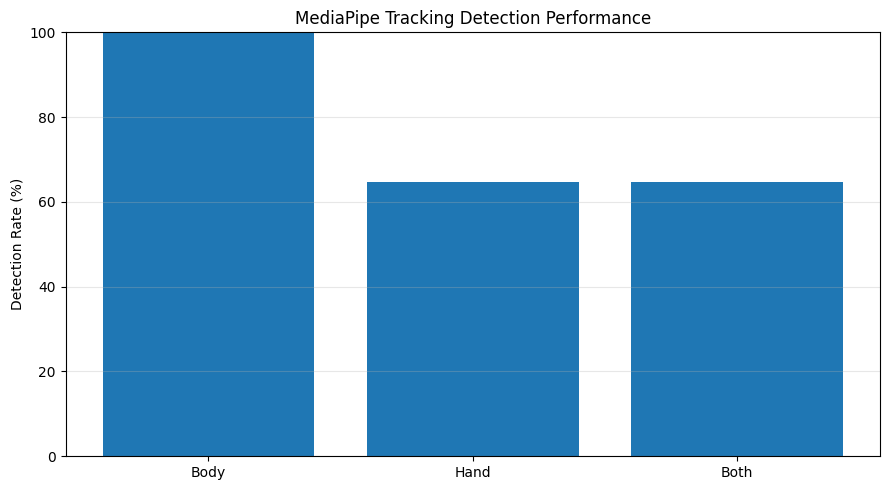

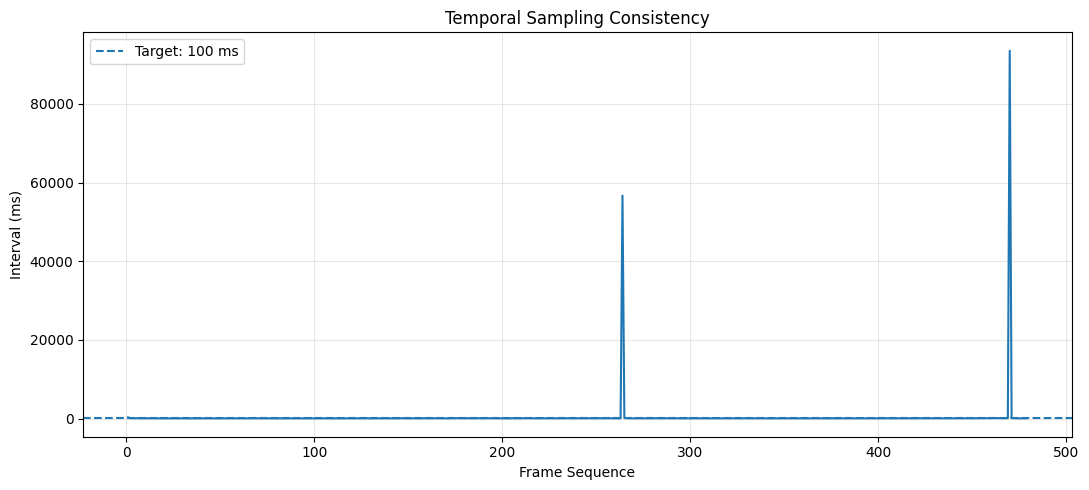

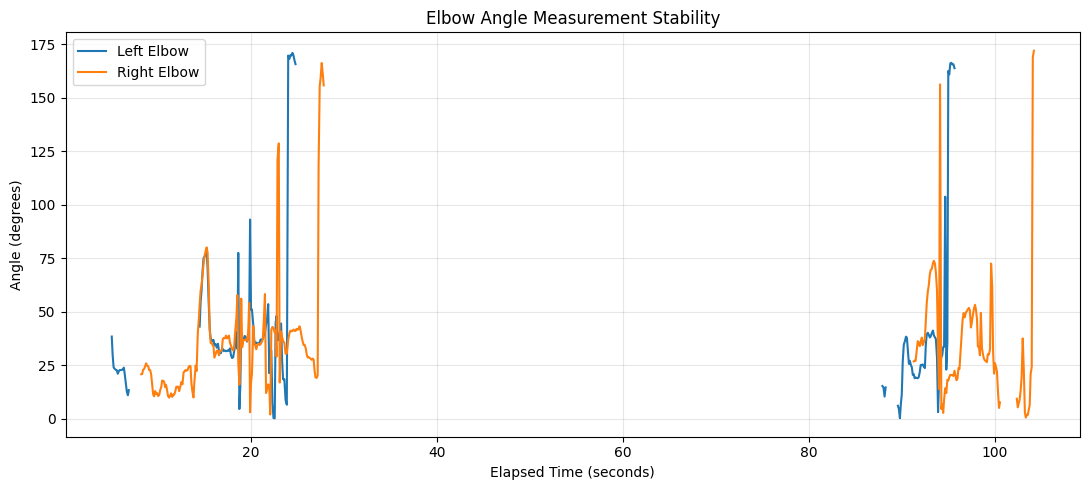

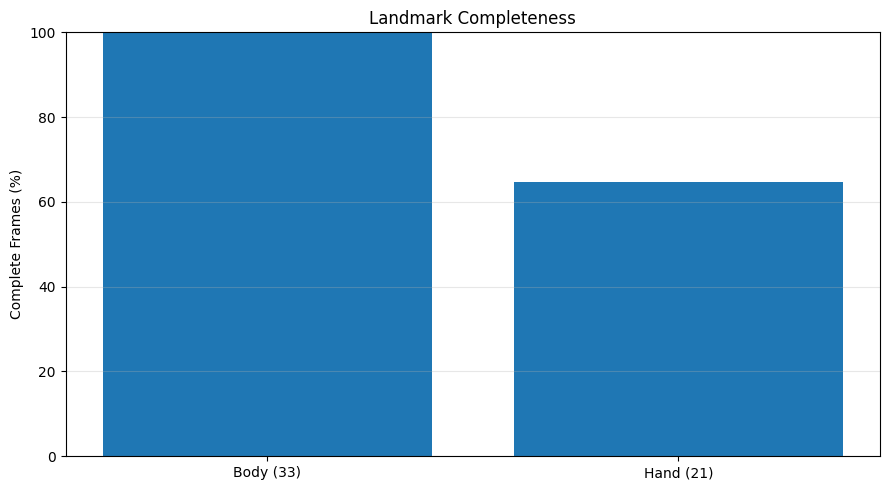


CELL 10 COMPLETED
Generated evaluation files:
cpr_algorithm_evaluation.csv
cpr_measurement_evaluation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Evaluation reports downloaded successfully!


In [ ]:

# ============================================================
# CELL 10: ALGORITHM / TRACKING PIPELINE EVALUATION
# Preliminary quantitative evaluation of MediaPipe CPR tracking
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

print("=" * 65)
print("CELL 10: ALGORITHM EVALUATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. UPLOAD CELL 9 FEATURE DATASET
# ------------------------------------------------------------

print("\nUpload: cpr_movement_features.csv")

uploaded = files.upload()

feature_file = next(
    (
        name for name in uploaded
        if "movement_features" in name.lower()
    ),
    None
)

if feature_file is None:
    raise FileNotFoundError(
        "Please upload cpr_movement_features.csv"
    )

df = pd.read_csv(feature_file)

print("\nDataset loaded successfully!")
print("Total records:", len(df))

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "elapsed_ms",
    "pose_detected",
    "hands_detected",
    "pose_landmark_count",
    "hand_landmark_count"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )

# ------------------------------------------------------------
# 3. CLEAN AND SORT DATA
# ------------------------------------------------------------

numeric_columns = [
    "elapsed_ms",
    "pose_detected",
    "hands_detected",
    "pose_landmark_count",
    "hand_landmark_count"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = (
    df.dropna(subset=["elapsed_ms"])
      .sort_values("elapsed_ms")
      .reset_index(drop=True)
)

if df.empty:
    raise ValueError("No valid frame records found.")

total_frames = len(df)

df["body_found"] = (
    df["pose_detected"].fillna(0) > 0
)

df["hand_found"] = (
    df["hands_detected"].fillna(0) > 0
)

df["both_found"] = (
    df["body_found"] & df["hand_found"]
)

# ------------------------------------------------------------
# 4. DETECTION PERFORMANCE
# ------------------------------------------------------------

body_frames = int(df["body_found"].sum())
hand_frames = int(df["hand_found"].sum())
both_frames = int(df["both_found"].sum())

body_rate = body_frames / total_frames * 100
hand_rate = hand_frames / total_frames * 100
both_rate = both_frames / total_frames * 100

print("\nDETECTION PERFORMANCE")
print("-" * 50)

print(f"Total frames: {total_frames}")
print(f"Body detected: {body_frames}")
print(f"Hand detected: {hand_frames}")
print(f"Both detected: {both_frames}")

print(f"Body detection rate: {body_rate:.2f}%")
print(f"Hand detection rate: {hand_rate:.2f}%")
print(f"Simultaneous detection rate: {both_rate:.2f}%")

# ------------------------------------------------------------
# 5. TEMPORAL CONSISTENCY
# ------------------------------------------------------------

elapsed_seconds = df["elapsed_ms"] / 1000.0

intervals = df["elapsed_ms"].diff().dropna()

median_interval = (
    intervals.median()
    if len(intervals) else np.nan
)

mean_interval = (
    intervals.mean()
    if len(intervals) else np.nan
)

estimated_fps = (
    1000 / median_interval
    if pd.notna(median_interval) and median_interval > 0
    else np.nan
)

sampling_consistency = (
    ((intervals >= 80) & (intervals <= 120)).mean() * 100
    if len(intervals) else np.nan
)

duration_seconds = (
    (df["elapsed_ms"].max() -
     df["elapsed_ms"].min()) / 1000
)

duplicate_timestamps = int(
    df["elapsed_ms"].duplicated().sum()
)

print("\nTEMPORAL CONSISTENCY")
print("-" * 50)

print(f"Recording duration: {duration_seconds:.2f} seconds")
print(f"Median frame interval: {median_interval:.2f} ms")
print(f"Mean frame interval: {mean_interval:.2f} ms")
print(f"Estimated sampling rate: {estimated_fps:.2f} FPS")
print(f"Intervals within 80-120 ms: {sampling_consistency:.2f}%")
print(f"Duplicate timestamps: {duplicate_timestamps}")

# ------------------------------------------------------------
# 6. LANDMARK COMPLETENESS
# ------------------------------------------------------------

body_count = pd.to_numeric(
    df["pose_landmark_count"],
    errors="coerce"
)

hand_count = pd.to_numeric(
    df["hand_landmark_count"],
    errors="coerce"
)

body_complete_frames = int(
    (body_count == 33).sum()
)

hand_complete_frames = int(
    (hand_count == 21).sum()
)

body_complete_rate = (
    body_complete_frames / total_frames * 100
)

hand_complete_rate = (
    hand_complete_frames / total_frames * 100
)

print("\nLANDMARK COMPLETENESS")
print("-" * 50)

print(
    f"Frames with 33 body landmarks: "
    f"{body_complete_frames} ({body_complete_rate:.2f}%)"
)

print(
    f"Frames with 21 hand landmarks: "
    f"{hand_complete_frames} ({hand_complete_rate:.2f}%)"
)

# ------------------------------------------------------------
# 7. MOVEMENT MEASUREMENT COVERAGE
# ------------------------------------------------------------

measurement_columns = [
    "left_elbow_angle_2d_deg",
    "right_elbow_angle_2d_deg",
    "left_elbow_angle_3d_deg",
    "right_elbow_angle_3d_deg",
    "shoulder_width_norm",
    "hand_body_wrist_distance_norm",
    "hand_wrist_speed_norm_per_sec",
    "left_wrist_speed_norm_per_sec",
    "right_wrist_speed_norm_per_sec"
]

measurement_results = []

for col in measurement_columns:

    if col not in df.columns:
        continue

    values = pd.to_numeric(
        df[col],
        errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    valid = values.dropna()

    measurement_results.append({

        "Measurement": col,

        "Valid Samples": len(valid),

        "Missing Samples": total_frames - len(valid),

        "Coverage (%)":
            len(valid) / total_frames * 100,

        "Mean": valid.mean() if len(valid) else np.nan,

        "Standard Deviation":
            valid.std() if len(valid) > 1 else np.nan,

        "Minimum": valid.min() if len(valid) else np.nan,

        "Maximum": valid.max() if len(valid) else np.nan

    })

measurement_df = pd.DataFrame(
    measurement_results
)

print("\nMEASUREMENT COVERAGE AND STATISTICS")
print("-" * 50)

display(
    measurement_df.round(4)
)

# ------------------------------------------------------------
# 8. CREATE OVERALL EVALUATION REPORT
# ------------------------------------------------------------

evaluation_results = [

    ("Total Frames", total_frames),

    ("Recording Duration (seconds)", duration_seconds),

    ("Body Detection Rate (%)", body_rate),

    ("Hand Detection Rate (%)", hand_rate),

    ("Simultaneous Detection Rate (%)", both_rate),

    ("Body Landmark Completeness (%)", body_complete_rate),

    ("Hand Landmark Completeness (%)", hand_complete_rate),

    ("Median Frame Interval (ms)", median_interval),

    ("Estimated Sampling Rate (FPS)", estimated_fps),

    ("Sampling Consistency (%)", sampling_consistency),

    ("Duplicate Timestamps", duplicate_timestamps)

]

evaluation_df = pd.DataFrame(
    evaluation_results,
    columns=["Evaluation Metric", "Result"]
)

print("\nOVERALL EVALUATION REPORT")
print("-" * 50)

display(
    evaluation_df.round(4)
)

# ------------------------------------------------------------
# 9. GRAPH 1: DETECTION RATES
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    ["Body", "Hand", "Both"],
    [body_rate, hand_rate, both_rate]
)

plt.ylim(0, 100)

plt.ylabel("Detection Rate (%)")
plt.title("MediaPipe Tracking Detection Performance")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. GRAPH 2: FRAME INTERVALS
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    np.arange(1, len(intervals) + 1),
    intervals.values
)

plt.axhline(
    100,
    linestyle="--",
    label="Target: 100 ms"
)

plt.xlabel("Frame Sequence")
plt.ylabel("Interval (ms)")
plt.title("Temporal Sampling Consistency")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. GRAPH 3: ELBOW ANGLE MEASUREMENTS
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    elapsed_seconds,
    df["left_elbow_angle_2d_deg"],
    label="Left Elbow"
)

plt.plot(
    elapsed_seconds,
    df["right_elbow_angle_2d_deg"],
    label="Right Elbow"
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Angle (degrees)")
plt.title("Elbow Angle Measurement Stability")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. GRAPH 4: LANDMARK COMPLETENESS
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    ["Body (33)", "Hand (21)"],
    [body_complete_rate, hand_complete_rate]
)

plt.ylim(0, 100)

plt.ylabel("Complete Frames (%)")
plt.title("Landmark Completeness")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. EXPORT RESULTS
# ------------------------------------------------------------

evaluation_file = "cpr_algorithm_evaluation.csv"

measurement_file = "cpr_measurement_evaluation.csv"

evaluation_df.to_csv(
    evaluation_file,
    index=False
)

measurement_df.to_csv(
    measurement_file,
    index=False
)

print("\n" + "=" * 65)
print("CELL 10 COMPLETED")
print("=" * 65)

print("Generated evaluation files:")
print(evaluation_file)
print(measurement_file)

# ------------------------------------------------------------
# 14. DOWNLOAD REPORTS
# ------------------------------------------------------------

files.download(evaluation_file)
files.download(measurement_file)

print("\nEvaluation reports downloaded successfully!")


CELL 11: DATA QUALITY VALIDATION

Upload BOTH original Cell 8 CSV files:
1. cpr_landmark_coordinates.csv
2. cpr_frame_summary.csv


Saving cpr_frame_summary.csv to cpr_frame_summary (1).csv
Saving cpr_landmark_coordinates.csv to cpr_landmark_coordinates (1).csv

Both datasets uploaded successfully!
Raw landmark records: 22350
Frame summary records: 480

DATA QUALITY SUMMARY


,Quality Metric,Result
0,Total recorded frames,480.0000
1,Recording duration (seconds),203.5550
2,Body detection rate (%),100.0000
3,Body complete frames (33/33) (%),100.0000
4,Body completeness when detected (%),100.0000
5,Hand detection rate (%),64.5833
6,Hand complete frames (21/21) (%),64.5833
7,Hand completeness when detected (%),100.0000
8,Median frame interval (ms),116.0000
9,Mean frame interval (ms),424.9582



BODY LANDMARK CONFIDENCE BY JOINT


,landmark_index,landmark_name,detected_frames,frame_coverage_percent,visibility_samples,mean_visibility,low_visibility_count,low_visibility_percent,presence_samples,mean_presence,low_presence_count,low_presence_percent
0,0,nose,480,100.0,480,0.9995,0,0.0000,0,NaN,0,NaN
1,1,left_eye_inner,480,100.0,480,0.9992,0,0.0000,0,NaN,0,NaN
2,2,left_eye,480,100.0,480,0.9991,0,0.0000,0,NaN,0,NaN
3,3,left_eye_outer,480,100.0,480,0.9991,0,0.0000,0,NaN,0,NaN
4,4,right_eye_inner,480,100.0,480,0.9993,0,0.0000,0,NaN,0,NaN
5,5,right_eye,480,100.0,480,0.9992,0,0.0000,0,NaN,0,NaN
6,6,right_eye_outer,480,100.0,480,0.9993,0,0.0000,0,NaN,0,NaN
7,7,left_ear,480,100.0,480,0.9991,0,0.0000,0,NaN,0,NaN
8,8,right_ear,480,100.0,480,0.9994,0,0.0000,0,NaN,0,NaN
9,9,mouth_left,480,100.0,480,0.9993,0,0.0000,0,NaN,0,NaN



HAND CLASSIFICATION SUMMARY


,handedness,detected_frames,mean_classification_score,minimum_classification_score
0,Left,122,0.9652,0.5384
1,Right,188,0.9775,0.6484



NORMALIZED COORDINATE CHECK


,model,coordinate,available_values,missing_values,outside_normalized_range_count,outside_normalized_range_percent
0,pose,x,15840,0,153,0.9659
1,pose,y,15840,0,7067,44.6149
2,hand,x,6510,0,56,0.8602
3,hand,y,6510,0,6,0.0922


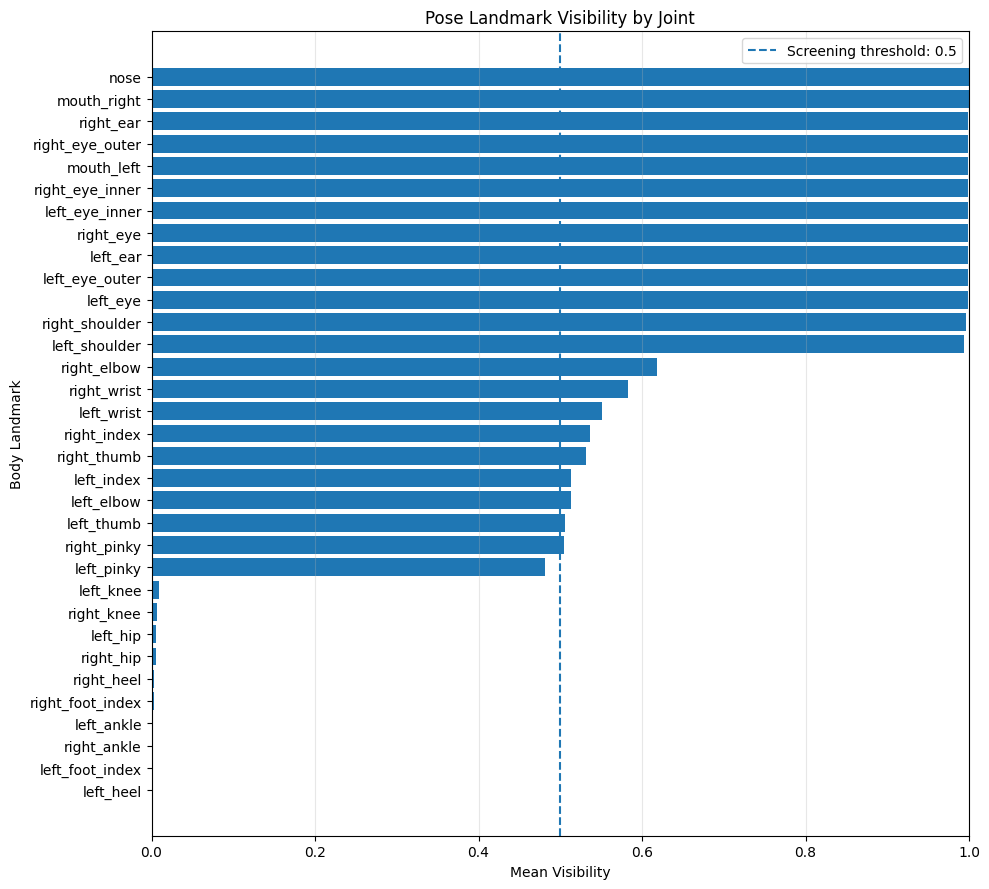

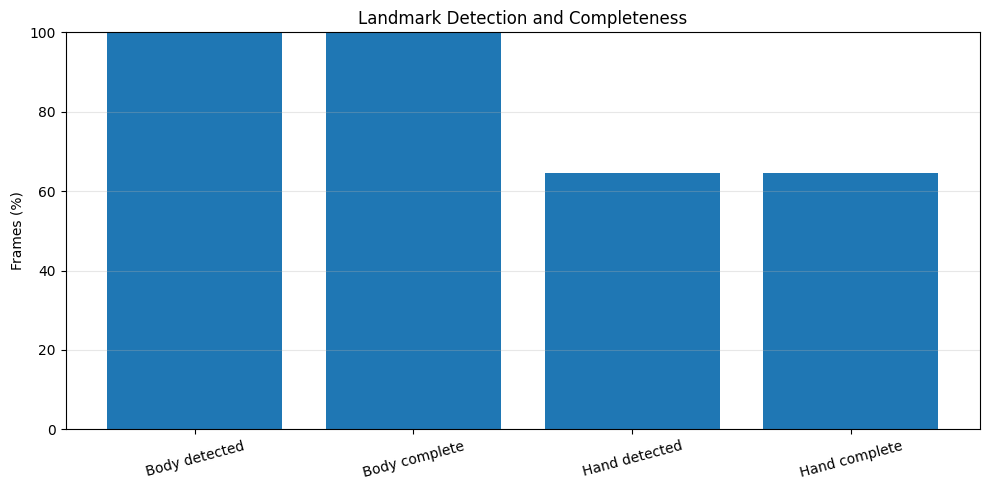

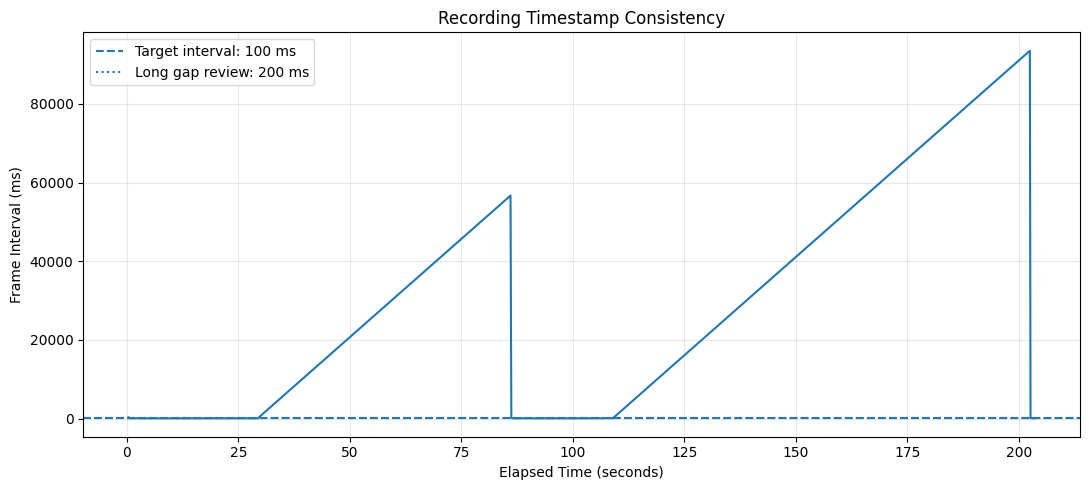

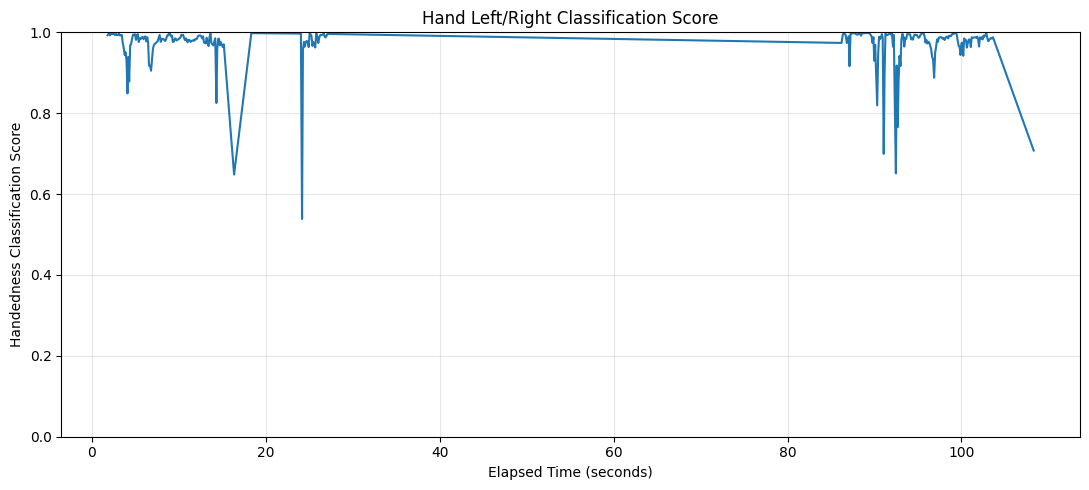


CELL 11 COMPLETED SUCCESSFULLY!

Generated reports:
- cpr_data_quality_summary.csv
- cpr_pose_landmark_confidence.csv
- cpr_hand_classification_quality.csv
- cpr_coordinate_quality.csv
- cpr_frame_quality_validation.csv



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CELL 11: DATA QUALITY AND LANDMARK CONFIDENCE VALIDATION
# Raw MediaPipe Hand + Body Landmark Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile

from google.colab import files
from IPython.display import display

print("=" * 65)
print("CELL 11: DATA QUALITY VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. UPLOAD ORIGINAL CELL 8 DATASETS
# ------------------------------------------------------------

print("\nUpload BOTH original Cell 8 CSV files:")
print("1. cpr_landmark_coordinates.csv")
print("2. cpr_frame_summary.csv")

uploaded = files.upload()

landmark_file = next(
    (n for n in uploaded if "landmark_coordinates" in n.lower()),
    None
)

frame_file = next(
    (n for n in uploaded if "frame_summary" in n.lower()),
    None
)

if landmark_file is None or frame_file is None:
    raise FileNotFoundError(
        "Please upload both original Cell 8 CSV files."
    )

landmarks = pd.read_csv(landmark_file)
frames = pd.read_csv(frame_file)

required = {
    "timestamp_ms", "elapsed_ms", "model",
    "landmark_index", "landmark_name", "x", "y", "z"
}

missing = required - set(landmarks.columns)

if missing:
    raise ValueError(
        f"Missing landmark columns: {sorted(missing)}"
    )

if not {"timestamp_ms", "elapsed_ms"}.issubset(frames.columns):
    raise ValueError("Frame summary is missing timestamp columns.")

print("\nBoth datasets uploaded successfully!")
print("Raw landmark records:", len(landmarks))
print("Frame summary records:", len(frames))

# ------------------------------------------------------------
# 2. CLEAN DATA TYPES
# ------------------------------------------------------------

landmarks["model"] = (
    landmarks["model"].astype(str).str.lower().str.strip()
)

numeric_cols = [
    "timestamp_ms", "elapsed_ms", "landmark_index",
    "x", "y", "z",
    "world_x", "world_y", "world_z",
    "visibility", "presence", "handedness_score"
]

for col in numeric_cols:
    if col in landmarks.columns:
        landmarks[col] = pd.to_numeric(
            landmarks[col], errors="coerce"
        )

for col in [
    "timestamp_ms", "elapsed_ms",
    "pose_detected", "hands_detected",
    "pose_landmark_count", "hand_landmark_count"
]:
    if col in frames.columns:
        frames[col] = pd.to_numeric(
            frames[col], errors="coerce"
        )

landmarks = landmarks.dropna(
    subset=["timestamp_ms", "landmark_index"]
).copy()

frames = frames.dropna(
    subset=["timestamp_ms", "elapsed_ms"]
).copy()

landmarks["timestamp_ms"] = (
    landmarks["timestamp_ms"].round().astype("int64")
)

frames["timestamp_ms"] = (
    frames["timestamp_ms"].round().astype("int64")
)

# ------------------------------------------------------------
# 3. REMOVE DUPLICATE FRAME SUMMARY ENTRIES
# ------------------------------------------------------------

duplicate_frame_summaries = int(
    frames["timestamp_ms"].duplicated().sum()
)

frames = (
    frames.sort_values("elapsed_ms")
    .drop_duplicates("timestamp_ms", keep="first")
    .reset_index(drop=True)
)

total_frames = len(frames)

if total_frames == 0:
    raise ValueError("No valid recording frames were found.")

# ------------------------------------------------------------
# 4. LANDMARK REFERENCE NAMES
# ------------------------------------------------------------

POSE_NAMES = [
    "nose",
    "left_eye_inner", "left_eye", "left_eye_outer",
    "right_eye_inner", "right_eye", "right_eye_outer",
    "left_ear", "right_ear",
    "mouth_left", "mouth_right",
    "left_shoulder", "right_shoulder",
    "left_elbow", "right_elbow",
    "left_wrist", "right_wrist",
    "left_pinky", "right_pinky",
    "left_index", "right_index",
    "left_thumb", "right_thumb",
    "left_hip", "right_hip",
    "left_knee", "right_knee",
    "left_ankle", "right_ankle",
    "left_heel", "right_heel",
    "left_foot_index", "right_foot_index"
]

HAND_NAMES = [
    "wrist", "thumb_cmc", "thumb_mcp", "thumb_ip",
    "thumb_tip", "index_finger_mcp", "index_finger_pip",
    "index_finger_dip", "index_finger_tip",
    "middle_finger_mcp", "middle_finger_pip",
    "middle_finger_dip", "middle_finger_tip",
    "ring_finger_mcp", "ring_finger_pip",
    "ring_finger_dip", "ring_finger_tip",
    "pinky_finger_mcp", "pinky_finger_pip",
    "pinky_finger_dip", "pinky_finger_tip"
]

# ------------------------------------------------------------
# 5. CHECK ACTUAL LANDMARK COUNTS PER FRAME
# ------------------------------------------------------------

def get_model_counts(data, model, prefix):

    subset = data[data["model"] == model].copy()

    if subset.empty:
        return pd.DataFrame(
            columns=[
                "timestamp_ms",
                f"{prefix}_rows",
                f"{prefix}_unique",
                f"{prefix}_duplicates"
            ]
        )

    grouped = (
        subset.groupby("timestamp_ms")
        .agg(
            rows=("landmark_index", "size"),
            unique=("landmark_index", "nunique"),
            duplicates=(
                "landmark_index",
                lambda x: int(x.duplicated().sum())
            )
        )
        .reset_index()
    )

    return grouped.rename(columns={
        "rows": f"{prefix}_rows",
        "unique": f"{prefix}_unique",
        "duplicates": f"{prefix}_duplicates"
    })


pose_counts = get_model_counts(
    landmarks, "pose", "pose"
)

hand_counts = get_model_counts(
    landmarks, "hand", "hand"
)

frame_quality = frames.merge(
    pose_counts, on="timestamp_ms", how="left"
)

frame_quality = frame_quality.merge(
    hand_counts, on="timestamp_ms", how="left"
)

for col in [
    "pose_rows", "pose_unique", "pose_duplicates",
    "hand_rows", "hand_unique", "hand_duplicates"
]:
    frame_quality[col] = frame_quality[col].fillna(0).astype(int)

# Use actual raw landmark records as the source of truth.
frame_quality["body_detected_actual"] = (
    frame_quality["pose_unique"] > 0
)

frame_quality["hand_detected_actual"] = (
    frame_quality["hand_unique"] > 0
)

frame_quality["body_complete_33"] = (
    frame_quality["pose_unique"] == 33
)

frame_quality["hand_complete_21"] = (
    frame_quality["hand_unique"] == 21
)

# ------------------------------------------------------------
# 6. BODY DETECTION AND COMPLETENESS
# ------------------------------------------------------------

body_detected_frames = int(
    frame_quality["body_detected_actual"].sum()
)

body_complete_frames = int(
    frame_quality["body_complete_33"].sum()
)

body_detection_rate = (
    body_detected_frames / total_frames * 100
)

body_complete_all_rate = (
    body_complete_frames / total_frames * 100
)

body_complete_detected_rate = (
    body_complete_frames / body_detected_frames * 100
    if body_detected_frames else np.nan
)

# ------------------------------------------------------------
# 7. HAND DETECTION AND COMPLETENESS
# ------------------------------------------------------------

hand_detected_frames = int(
    frame_quality["hand_detected_actual"].sum()
)

hand_complete_frames = int(
    frame_quality["hand_complete_21"].sum()
)

hand_detection_rate = (
    hand_detected_frames / total_frames * 100
)

hand_complete_all_rate = (
    hand_complete_frames / total_frames * 100
)

hand_complete_detected_rate = (
    hand_complete_frames / hand_detected_frames * 100
    if hand_detected_frames else np.nan
)

# ------------------------------------------------------------
# 8. POSE LANDMARK VISIBILITY AND PRESENCE
# ------------------------------------------------------------

VISIBILITY_THRESHOLD = 0.5
PRESENCE_THRESHOLD = 0.5

pose_data = landmarks[
    landmarks["model"] == "pose"
].copy()

# One record per timestamp and joint.
pose_data = pose_data.drop_duplicates(
    ["timestamp_ms", "landmark_index"],
    keep="first"
)

pose_confidence_rows = []

for index in range(33):

    joint = pose_data[
        pose_data["landmark_index"] == index
    ].copy()

    if joint.empty:
        continue

    visibility = (
        pd.to_numeric(joint["visibility"], errors="coerce")
        if "visibility" in joint.columns
        else pd.Series(dtype=float)
    )

    presence = (
        pd.to_numeric(joint["presence"], errors="coerce")
        if "presence" in joint.columns
        else pd.Series(dtype=float)
    )

    visibility_valid = visibility.dropna()
    presence_valid = presence.dropna()

    joint_name = (
        joint["landmark_name"].dropna().iloc[0]
        if joint["landmark_name"].notna().any()
        else POSE_NAMES[index]
    )

    pose_confidence_rows.append({

        "landmark_index": index,
        "landmark_name": joint_name,

        "detected_frames": joint["timestamp_ms"].nunique(),

        "frame_coverage_percent":
            joint["timestamp_ms"].nunique() / total_frames * 100,

        "visibility_samples": len(visibility_valid),

        "mean_visibility":
            visibility_valid.mean()
            if len(visibility_valid) else np.nan,

        "low_visibility_count":
            int((visibility_valid < VISIBILITY_THRESHOLD).sum()),

        "low_visibility_percent":
            (visibility_valid < VISIBILITY_THRESHOLD).mean() * 100
            if len(visibility_valid) else np.nan,

        "presence_samples": len(presence_valid),

        "mean_presence":
            presence_valid.mean()
            if len(presence_valid) else np.nan,

        "low_presence_count":
            int((presence_valid < PRESENCE_THRESHOLD).sum()),

        "low_presence_percent":
            (presence_valid < PRESENCE_THRESHOLD).mean() * 100
            if len(presence_valid) else np.nan

    })

pose_confidence_df = pd.DataFrame(
    pose_confidence_rows
)

# ------------------------------------------------------------
# 9. HAND HANDEDNESS CLASSIFICATION QUALITY
# ------------------------------------------------------------

hand_data = landmarks[
    landmarks["model"] == "hand"
].copy()

# Only one representative row per detected hand/frame.
hand_classification = (
    hand_data[
        hand_data["landmark_index"] == 0
    ]
    .drop_duplicates("timestamp_ms")
    .copy()
)

if "handedness_score" in hand_classification.columns:

    hand_classification["handedness_score"] = pd.to_numeric(
        hand_classification["handedness_score"],
        errors="coerce"
    )

if "handedness" not in hand_classification.columns:
    hand_classification["handedness"] = ""

hand_scores = (
    hand_classification["handedness_score"].dropna()
    if "handedness_score" in hand_classification.columns
    else pd.Series(dtype=float)
)

handedness_summary = (
    hand_classification.groupby("handedness")
    .agg(
        detected_frames=("timestamp_ms", "nunique"),
        mean_classification_score=(
            "handedness_score", "mean"
        ),
        minimum_classification_score=(
            "handedness_score", "min"
        )
    )
    .reset_index()
    if not hand_classification.empty
    else pd.DataFrame()
)

# ------------------------------------------------------------
# 10. TIMESTAMP AND RECORDING GAP VALIDATION
# ------------------------------------------------------------

frame_quality = frame_quality.sort_values(
    "elapsed_ms"
).reset_index(drop=True)

elapsed = frame_quality["elapsed_ms"]

intervals = elapsed.diff().dropna()

median_interval = (
    intervals.median() if len(intervals) else np.nan
)

mean_interval = (
    intervals.mean() if len(intervals) else np.nan
)

p90_interval = (
    intervals.quantile(0.90) if len(intervals) else np.nan
)

estimated_fps = (
    1000 / median_interval
    if pd.notna(median_interval) and median_interval > 0
    else np.nan
)

within_target = (
    ((intervals >= 80) & (intervals <= 120)).mean() * 100
    if len(intervals) else np.nan
)

gaps_over_200 = int((intervals > 200).sum())
gaps_over_500 = int((intervals > 500).sum())

recording_duration = (
    (elapsed.max() - elapsed.min()) / 1000
)

frame_quality["interval_ms"] = elapsed.diff()

frame_quality["long_gap_over_200ms"] = (
    frame_quality["interval_ms"] > 200
)

frame_quality["long_gap_over_500ms"] = (
    frame_quality["interval_ms"] > 500
)

# ------------------------------------------------------------
# 11. NORMALIZED COORDINATE RANGE CHECK
# ------------------------------------------------------------

coordinate_rows = []

for model in ["pose", "hand"]:

    subset = landmarks[
        landmarks["model"] == model
    ]

    for axis in ["x", "y"]:

        values = pd.to_numeric(
            subset[axis],
            errors="coerce"
        ).dropna()

        outside = (
            (values < 0) | (values > 1)
        )

        coordinate_rows.append({

            "model": model,
            "coordinate": axis,
            "available_values": len(values),

            "missing_values": int(
                subset[axis].isna().sum()
            ),

            "outside_normalized_range_count": int(
                outside.sum()
            ),

            "outside_normalized_range_percent": (
                outside.mean() * 100
                if len(values) else np.nan
            )

        })

coordinate_quality_df = pd.DataFrame(
    coordinate_rows
)

# Out-of-frame normalized x/y values are flagged for review,
# not automatically discarded.

# ------------------------------------------------------------
# 12. DUPLICATE RECORD VALIDATION
# ------------------------------------------------------------

duplicate_landmark_rows = int(
    landmarks.duplicated(
        ["timestamp_ms", "model", "landmark_index"]
    ).sum()
)

# ------------------------------------------------------------
# 13. BUILD QUALITY SUMMARY
# ------------------------------------------------------------

summary_rows = [

    ("Total recorded frames", total_frames),

    ("Recording duration (seconds)", recording_duration),

    ("Body detection rate (%)", body_detection_rate),

    ("Body complete frames (33/33) (%)", body_complete_all_rate),

    ("Body completeness when detected (%)",
     body_complete_detected_rate),

    ("Hand detection rate (%)", hand_detection_rate),

    ("Hand complete frames (21/21) (%)", hand_complete_all_rate),

    ("Hand completeness when detected (%)",
     hand_complete_detected_rate),

    ("Median frame interval (ms)", median_interval),

    ("Mean frame interval (ms)", mean_interval),

    ("90th percentile frame interval (ms)", p90_interval),

    ("Estimated sampling rate (FPS)", estimated_fps),

    ("Intervals within 80-120 ms (%)", within_target),

    ("Gaps over 200 ms", gaps_over_200),

    ("Gaps over 500 ms", gaps_over_500),

    ("Duplicate frame summary entries",
     duplicate_frame_summaries),

    ("Duplicate landmark records",
     duplicate_landmark_rows),

    ("Mean pose visibility",
     pose_confidence_df["mean_visibility"].mean()
     if (
         not pose_confidence_df.empty and
         "mean_visibility" in pose_confidence_df
     )
     else np.nan),

    ("Mean pose presence",
     pose_confidence_df["mean_presence"].mean()
     if (
         not pose_confidence_df.empty and
         "mean_presence" in pose_confidence_df
     )
     else np.nan),

    ("Mean hand handedness score",
     hand_scores.mean() if len(hand_scores) else np.nan)

]

quality_summary_df = pd.DataFrame(
    summary_rows,
    columns=["Quality Metric", "Result"]
)

# ------------------------------------------------------------
# 14. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATA QUALITY SUMMARY")
print("=" * 65)

display(quality_summary_df.round(4))

print("\nBODY LANDMARK CONFIDENCE BY JOINT")
display(pose_confidence_df.round(4))

print("\nHAND CLASSIFICATION SUMMARY")
if not handedness_summary.empty:
    display(handedness_summary.round(4))
else:
    print("No hand classification records available.")

print("\nNORMALIZED COORDINATE CHECK")
display(coordinate_quality_df.round(4))

# ------------------------------------------------------------
# 15. GRAPH 1: BODY JOINT VISIBILITY
# ------------------------------------------------------------

if (
    not pose_confidence_df.empty and
    pose_confidence_df["mean_visibility"].notna().any()
):

    plot_data = pose_confidence_df.dropna(
        subset=["mean_visibility"]
    ).sort_values("mean_visibility")

    plt.figure(figsize=(10, 9))

    plt.barh(
        plot_data["landmark_name"],
        plot_data["mean_visibility"]
    )

    plt.axvline(
        VISIBILITY_THRESHOLD,
        linestyle="--",
        label="Screening threshold: 0.5"
    )

    plt.xlim(0, 1)
    plt.xlabel("Mean Visibility")
    plt.ylabel("Body Landmark")
    plt.title("Pose Landmark Visibility by Joint")
    plt.legend()
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("\nNo pose visibility values available for plotting.")

# ------------------------------------------------------------
# 16. GRAPH 2: HAND DETECTION AND FRAME COMPLETENESS
# ------------------------------------------------------------

labels = [
    "Body detected",
    "Body complete",
    "Hand detected",
    "Hand complete"
]

values = [
    body_detection_rate,
    body_complete_all_rate,
    hand_detection_rate,
    hand_complete_all_rate
]

plt.figure(figsize=(10, 5))

plt.bar(labels, values)

plt.ylim(0, 100)
plt.ylabel("Frames (%)")
plt.title("Landmark Detection and Completeness")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 17. GRAPH 3: TIMESTAMP INTERVALS
# ------------------------------------------------------------

if len(intervals):

    plt.figure(figsize=(11, 5))

    plt.plot(
        frame_quality["elapsed_ms"].iloc[1:] / 1000,
        intervals.values
    )

    plt.axhline(
        100,
        linestyle="--",
        label="Target interval: 100 ms"
    )

    plt.axhline(
        200,
        linestyle=":",
        label="Long gap review: 200 ms"
    )

    plt.xlabel("Elapsed Time (seconds)")
    plt.ylabel("Frame Interval (ms)")
    plt.title("Recording Timestamp Consistency")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 18. GRAPH 4: HAND CLASSIFICATION SCORE
# ------------------------------------------------------------

if (
    not hand_classification.empty and
    "handedness_score" in hand_classification.columns
):

    plot_hand = hand_classification.dropna(
        subset=["handedness_score"]
    ).sort_values("elapsed_ms")

    if not plot_hand.empty:

        plt.figure(figsize=(11, 5))

        plt.plot(
            plot_hand["elapsed_ms"] / 1000,
            plot_hand["handedness_score"]
        )

        plt.ylim(0, 1)
        plt.xlabel("Elapsed Time (seconds)")
        plt.ylabel("Handedness Classification Score")
        plt.title("Hand Left/Right Classification Score")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 19. EXPORT QUALITY REPORTS
# ------------------------------------------------------------

summary_file = "cpr_data_quality_summary.csv"
pose_file = "cpr_pose_landmark_confidence.csv"
hand_file = "cpr_hand_classification_quality.csv"
coordinate_file = "cpr_coordinate_quality.csv"
frame_file_out = "cpr_frame_quality_validation.csv"

quality_summary_df.to_csv(summary_file, index=False)

pose_confidence_df.to_csv(pose_file, index=False)

handedness_summary.to_csv(hand_file, index=False)

coordinate_quality_df.to_csv(
    coordinate_file, index=False
)

frame_quality.to_csv(
    frame_file_out, index=False
)

# ------------------------------------------------------------
# 20. PACKAGE REPORTS INTO ONE ZIP FILE
# ------------------------------------------------------------

report_files = [
    summary_file,
    pose_file,
    hand_file,
    coordinate_file,
    frame_file_out
]

zip_file = "CPR_Cell11_Data_Quality_Reports.zip"

with zipfile.ZipFile(
    zip_file, "w", zipfile.ZIP_DEFLATED
) as archive:

    for filename in report_files:
        archive.write(filename)

print("\n" + "=" * 65)
print("CELL 11 COMPLETED SUCCESSFULLY!")
print("=" * 65)

print("\nGenerated reports:")

for filename in report_files:
    print("-", filename)

print("\nDownloading combined ZIP report...")

files.download(zip_file)
